# Earthquake Damage Prediction

**Project ID:** PRCP-1015-EquakeDamagePred

## 1. Project Introduction

Earthquakes can cause significant damage to buildings, infrastructure and human lives. The extent of damage depends on several factors, including building construction materials, foundation type, structural design, geographical location and building age.

This project aims to analyze earthquake-related building data and develop a Machine Learning classification model to predict the severity of damage caused to buildings during an earthquake.

The project uses the Nepal Earthquake dataset, which contains information about buildings affected by the 2015 Gorkha earthquake.

## 2. Problem Statement

The objective is to predict the ordinal target variable `damage_grade`, which represents the level of damage experienced by a building.

The target variable has three categories:

- **Grade 1:** Low damage
- **Grade 2:** Medium damage
- **Grade 3:** Almost complete destruction

## 3. Project Objectives

1. Perform comprehensive Exploratory Data Analysis (EDA).
2. Understand the structural and geographical factors associated with building damage.
3. Clean and preprocess the dataset.
4. Perform feature engineering where required.
5. Build and compare multiple Machine Learning classification models.
6. Select the best-performing model based on evaluation metrics.
7. Identify important features influencing building damage.
8. Provide recommendations to seismologists and policymakers to reduce earthquake-related building damage.

## 4. Business Objective

Develop a reliable predictive model that can help identify buildings that may be more vulnerable to earthquake damage and support better disaster preparedness, structural safety planning and risk-reduction decisions.

## 5. Machine Learning Approach

This project is an Ordinal Multiclass Classification problem because the target variable contains three ordered categories: 1, 2 and 3.

Step 3. Import the required libraries

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    mean_absolute_error
)

# Other libraries
import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


Step 4. Load the datasets

In [2]:
# Load training data
train_values = pd.read_csv("../dataset/train_values.csv")

# Load target labels
train_labels = pd.read_csv("../dataset/train_labels.csv")

print("Training features loaded successfully!")
print("Training labels loaded successfully!")

Training features loaded successfully!
Training labels loaded successfully!


In [3]:
print("Train Values Shape:", train_values.shape)
print("Train Labels Shape:", train_labels.shape)

Train Values Shape: (260601, 39)
Train Labels Shape: (260601, 2)


In [4]:
print("Training Features:")
display(train_values.head())

print("Training Labels:")
display(train_labels.head())

Training Features:


,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
0,802906,6,487,12198,2,30,6,5,t,r,n,f,q,t,d,1,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
1,28830,8,900,2812,2,10,8,7,o,r,n,x,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
2,94947,21,363,8973,2,10,5,5,t,r,n,f,x,t,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
3,590882,22,418,10694,2,10,6,5,t,r,n,f,x,s,d,0,1,0,0,0,0,1,1,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
4,201944,11,131,1488,3,30,8,9,t,r,n,f,x,s,d,1,0,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0


Training Labels:


,building_id,damage_grade
0,802906,3
1,28830,2
2,94947,3
3,590882,2
4,201944,3


In [5]:
print("Feature Columns:")
print(train_values.columns.tolist())

print("\nTarget Columns:")
print(train_labels.columns.tolist())

Feature Columns:
['building_id', 'geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id', 'count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_cement_mortar_brick', 'has_superstructure_timber', 'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered', 'has_superstructure_other', 'legal_ownership_status', 'count_families', 'has_secondary_use', 'has_secondary_use_agriculture', 'has_secondary_use_hotel', 'has_secondary_use_rental', 'has_secondary_use_institution', 'has_secondary_use_school', 'has_secondary_use_industry', 'has_secondary_use_health_post', 'has_secondary_use_gov_office', 'has_seconda

Step 5. Combine both datasets

In [6]:
# Merge features and target labels
df = pd.merge(
    train_values,
    train_labels,
    on="building_id",
    how="inner",
    validate="one_to_one"
)

print("Datasets merged successfully!")
print("Final Dataset Shape:", df.shape)

display(df.head())

Datasets merged successfully!
Final Dataset Shape: (260601, 40)


,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,802906,6,487,12198,2,30,6,5,t,r,n,f,q,t,d,1,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
1,28830,8,900,2812,2,10,8,7,o,r,n,x,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
2,94947,21,363,8973,2,10,5,5,t,r,n,f,x,t,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
3,590882,22,418,10694,2,10,6,5,t,r,n,f,x,s,d,0,1,0,0,0,0,1,1,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
4,201944,11,131,1488,3,30,8,9,t,r,n,f,x,s,d,1,0,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3


In [7]:
print("Feature records:", len(train_values))
print("Label records:", len(train_labels))
print("Merged records:", len(df))

print(
    "All records matched:",
    len(df) == len(train_values) == len(train_labels)
)

Feature records: 260601
Label records: 260601
Merged records: 260601
All records matched: True


Step 6. Initial dataset understanding

A. Dataset information

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260601 entries, 0 to 260600
Data columns (total 40 columns):
 #   Column                                  Non-Null Count   Dtype 
---  ------                                  --------------   ----- 
 0   building_id                             260601 non-null  int64 
 1   geo_level_1_id                          260601 non-null  int64 
 2   geo_level_2_id                          260601 non-null  int64 
 3   geo_level_3_id                          260601 non-null  int64 
 4   count_floors_pre_eq                     260601 non-null  int64 
 5   age                                     260601 non-null  int64 
 6   area_percentage                         260601 non-null  int64 
 7   height_percentage                       260601 non-null  int64 
 8   land_surface_condition                  260601 non-null  object
 9   foundation_type                         260601 non-null  object
 10  roof_type                               260601 non-null 

B. Statistical summary

In [9]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
building_id,260601.0,525675.482773,304544.999032,4.0,261190.0,525757.0,789762.0,1052934.0
geo_level_1_id,260601.0,13.900353,8.033617,0.0,7.0,12.0,21.0,30.0
geo_level_2_id,260601.0,701.074685,412.710734,0.0,350.0,702.0,1050.0,1427.0
geo_level_3_id,260601.0,6257.876148,3646.369645,0.0,3073.0,6270.0,9412.0,12567.0
count_floors_pre_eq,260601.0,2.129723,0.727665,1.0,2.0,2.0,2.0,9.0
age,260601.0,26.535029,73.565937,0.0,10.0,15.0,30.0,995.0
area_percentage,260601.0,8.018051,4.392231,1.0,5.0,7.0,9.0,100.0
height_percentage,260601.0,5.434365,1.918418,2.0,4.0,5.0,6.0,32.0
has_superstructure_adobe_mud,260601.0,0.088645,0.284231,0.0,0.0,0.0,0.0,1.0
has_superstructure_mud_mortar_stone,260601.0,0.761935,0.425900,0.0,1.0,1.0,1.0,1.0


In [10]:
display(df.describe(include="object").T)

,count,unique,top,freq
land_surface_condition,260601,3,t,216757
foundation_type,260601,5,r,219196
roof_type,260601,3,n,182842
ground_floor_type,260601,5,f,209619
other_floor_type,260601,4,q,165282
position,260601,4,s,202090
plan_configuration,260601,10,d,250072
legal_ownership_status,260601,4,v,250939


C. Check missing values

In [11]:
missing_values = df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": (
        missing_values / len(df)
    ) * 100
})

missing_report = missing_report.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_report)

,Missing_Count,Missing_Percentage
building_id,0,0.0
geo_level_1_id,0,0.0
has_superstructure_bamboo,0,0.0
has_superstructure_rc_non_engineered,0,0.0
has_superstructure_rc_engineered,0,0.0
has_superstructure_other,0,0.0
legal_ownership_status,0,0.0
count_families,0,0.0
has_secondary_use,0,0.0
has_secondary_use_agriculture,0,0.0


D. Check duplicate records

In [12]:
print("Total duplicate rows:", df.duplicated().sum())

print(
    "Duplicate building IDs:",
    df["building_id"].duplicated().sum()
)

Total duplicate rows: 0
Duplicate building IDs: 0


E. Check target variable

In [13]:
print("Damage Grade Distribution:")

display(
    df["damage_grade"].value_counts().sort_index()
)

print("\nDamage Grade Percentage:")

display(
    df["damage_grade"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

Damage Grade Distribution:


damage_grade
1     25124
2    148259
3     87218
Name: count, dtype: int64


Damage Grade Percentage:


damage_grade
1     9.64
2    56.89
3    33.47
Name: proportion, dtype: float64

## 6. Initial Data Quality and Target Variable Observations

### Dataset Overview
The dataset contains 260,601 building records and 40 columns after combining the feature and target datasets.

### Data Quality Findings
- No missing values were identified.
- No duplicate records were found.
- No duplicate building identifiers were detected.
- The dataset contains 32 integer columns and 8 categorical object columns.

### Target Variable Analysis
The target variable `damage_grade` contains three classes:

- Grade 1: 25,124 records (9.64%)
- Grade 2: 148,259 records (56.89%)
- Grade 3: 87,218 records (33.47%)

### Key Observations
1. Grade 2 is the most frequently occurring damage category.
2. Grade 1 is the minority class.
3. The target variable shows an imbalance between the three classes.
4. Missing-value treatment is not required based on the initial checks.
5. Duplicate removal is not required.

### Initial Decisions
- Retain all valid observations.
- Exclude `building_id` from predictive features.
- Investigate class imbalance during model development.
- Perform further analysis to understand the relationship between building characteristics and damage severity.

Exploratory Data Analysis (EDA)

Step 1. Set visualization preferences

In [14]:
# Visualization settings

sns.set_theme(style="whitegrid", palette="Set2")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

print("EDA visualization settings configured successfully!")

EDA visualization settings configured successfully!


Step 2. Univariate analysis — Numerical features

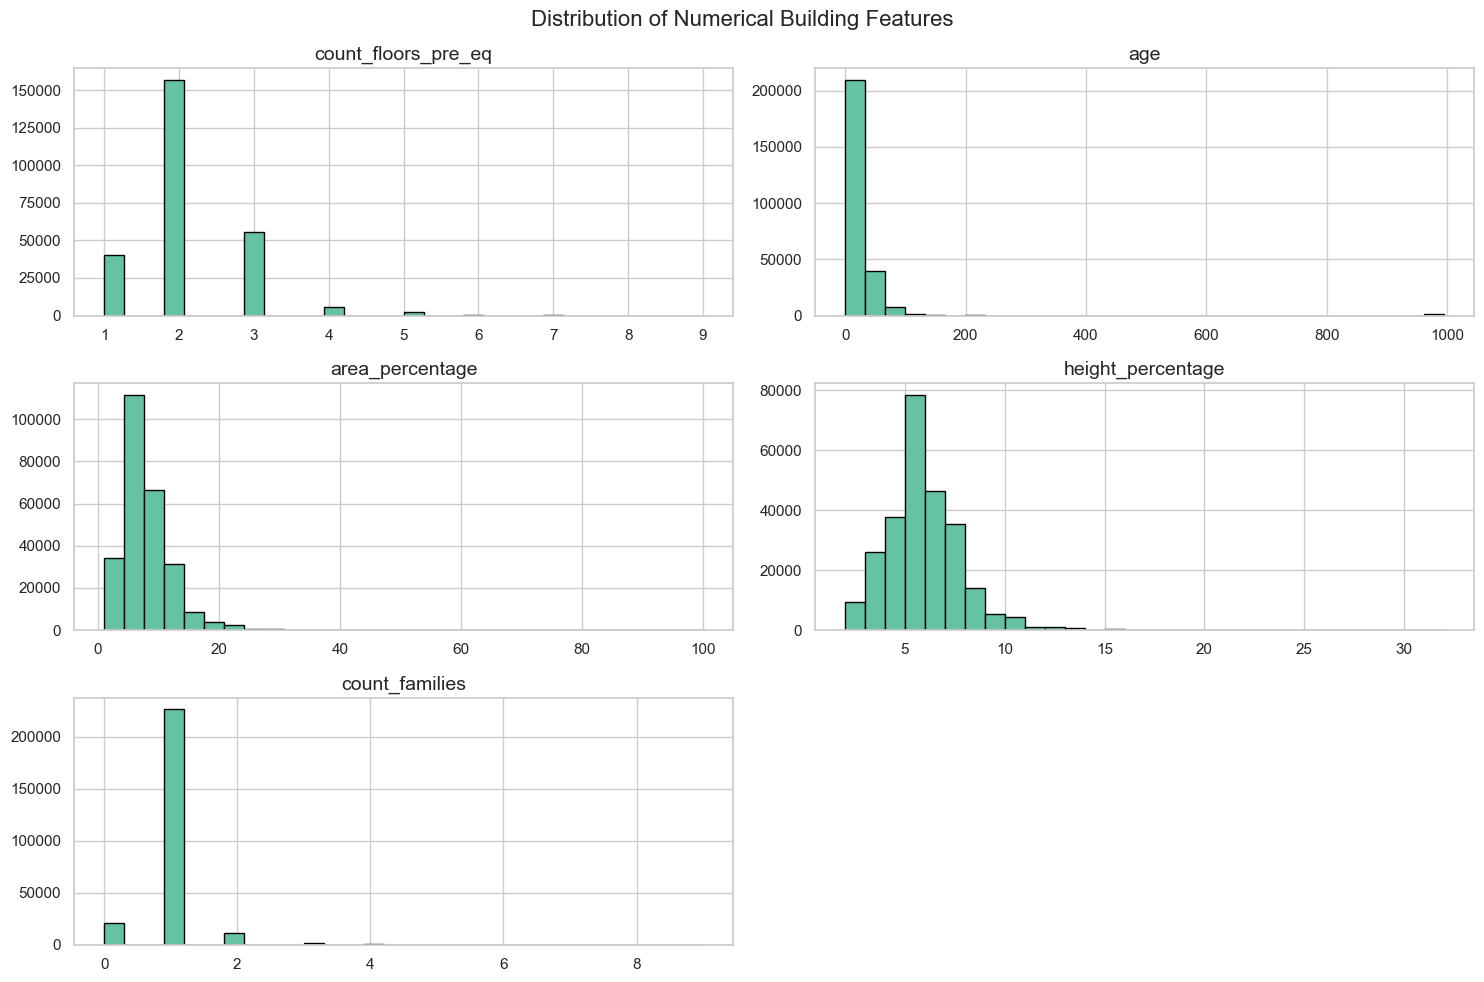

In [15]:
# Select meaningful numerical building features

numerical_features = [
    "count_floors_pre_eq",
    "age",
    "area_percentage",
    "height_percentage",
    "count_families"
]

# Plot distributions
df[numerical_features].hist(
    bins=30,
    figsize=(15, 10),
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Building Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

Step 3. Numerical features versus damage grade

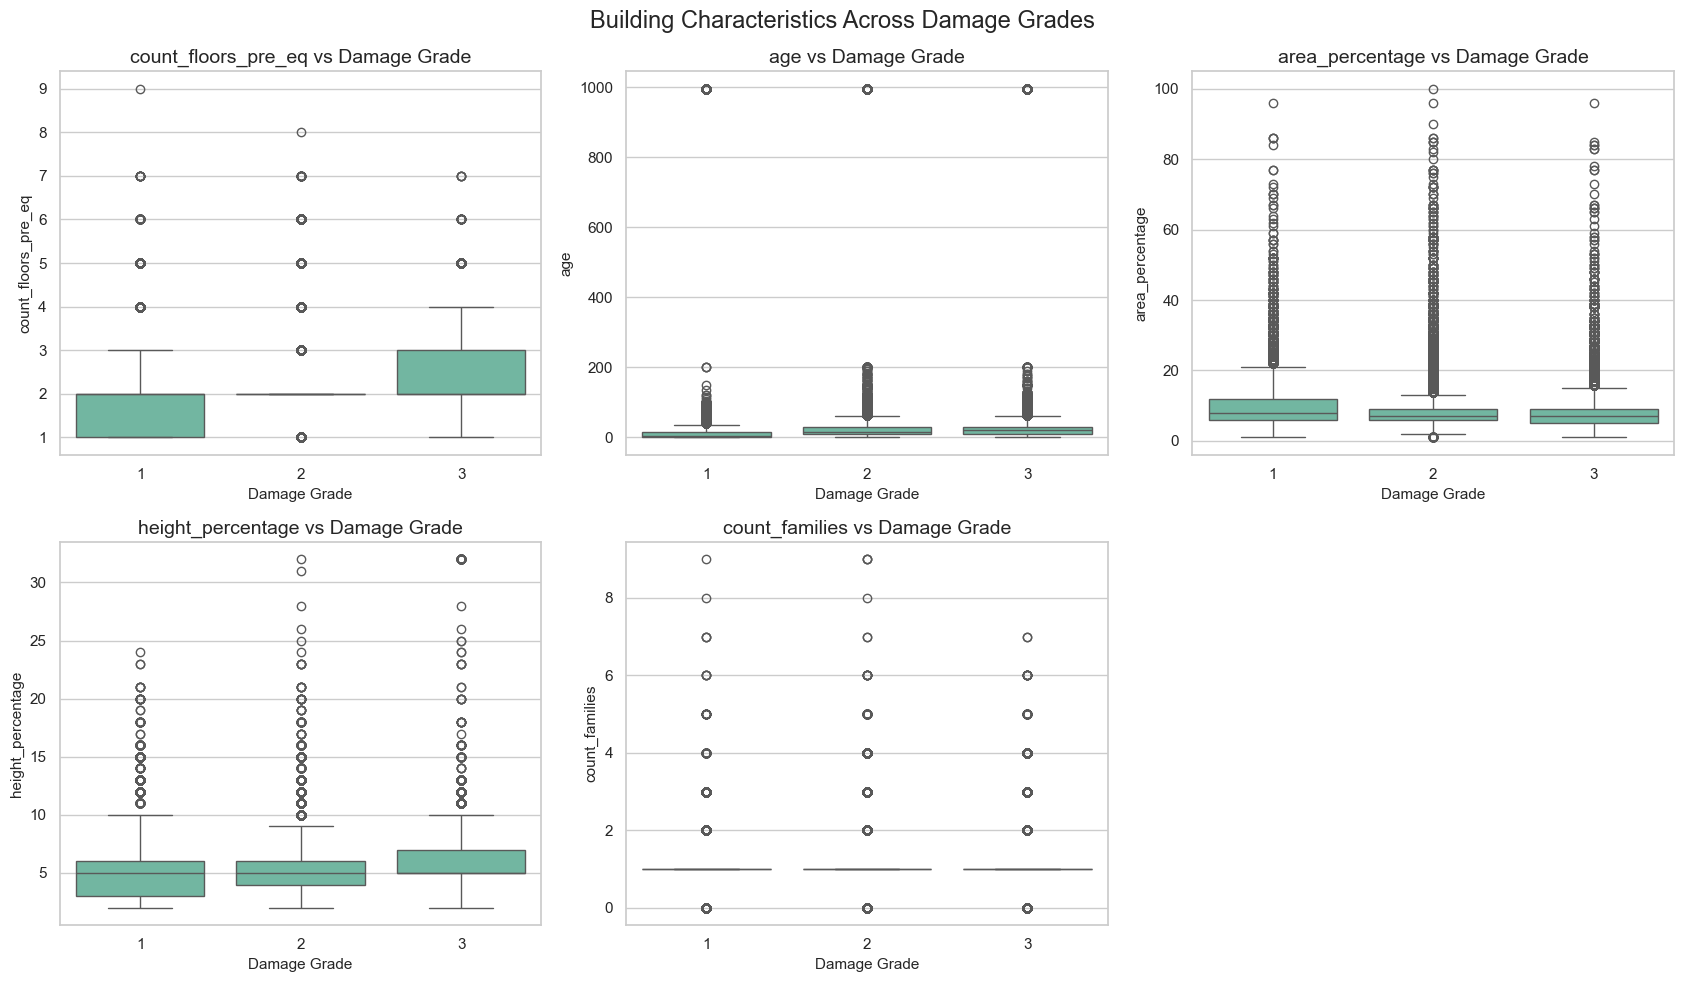

In [16]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 10)
)

for ax, feature in zip(
    axes.flatten(),
    numerical_features
):
    sns.boxplot(
        data=df,
        x="damage_grade",
        y=feature,
        ax=ax
    )

    ax.set_title(f"{feature} vs Damage Grade")
    ax.set_xlabel("Damage Grade")
    ax.set_ylabel(feature)

# Hide the unused subplot
axes.flatten()[-1].set_visible(False)

plt.suptitle(
    "Building Characteristics Across Damage Grades",
    fontsize=17
)

plt.tight_layout()
plt.show()

Step 4. Categorical feature analysis

In [17]:
categorical_features = [
    "land_surface_condition",
    "foundation_type",
    "roof_type",
    "ground_floor_type",
    "other_floor_type",
    "position",
    "plan_configuration",
    "legal_ownership_status"
]

print("Total categorical features:", len(categorical_features))

Total categorical features: 8


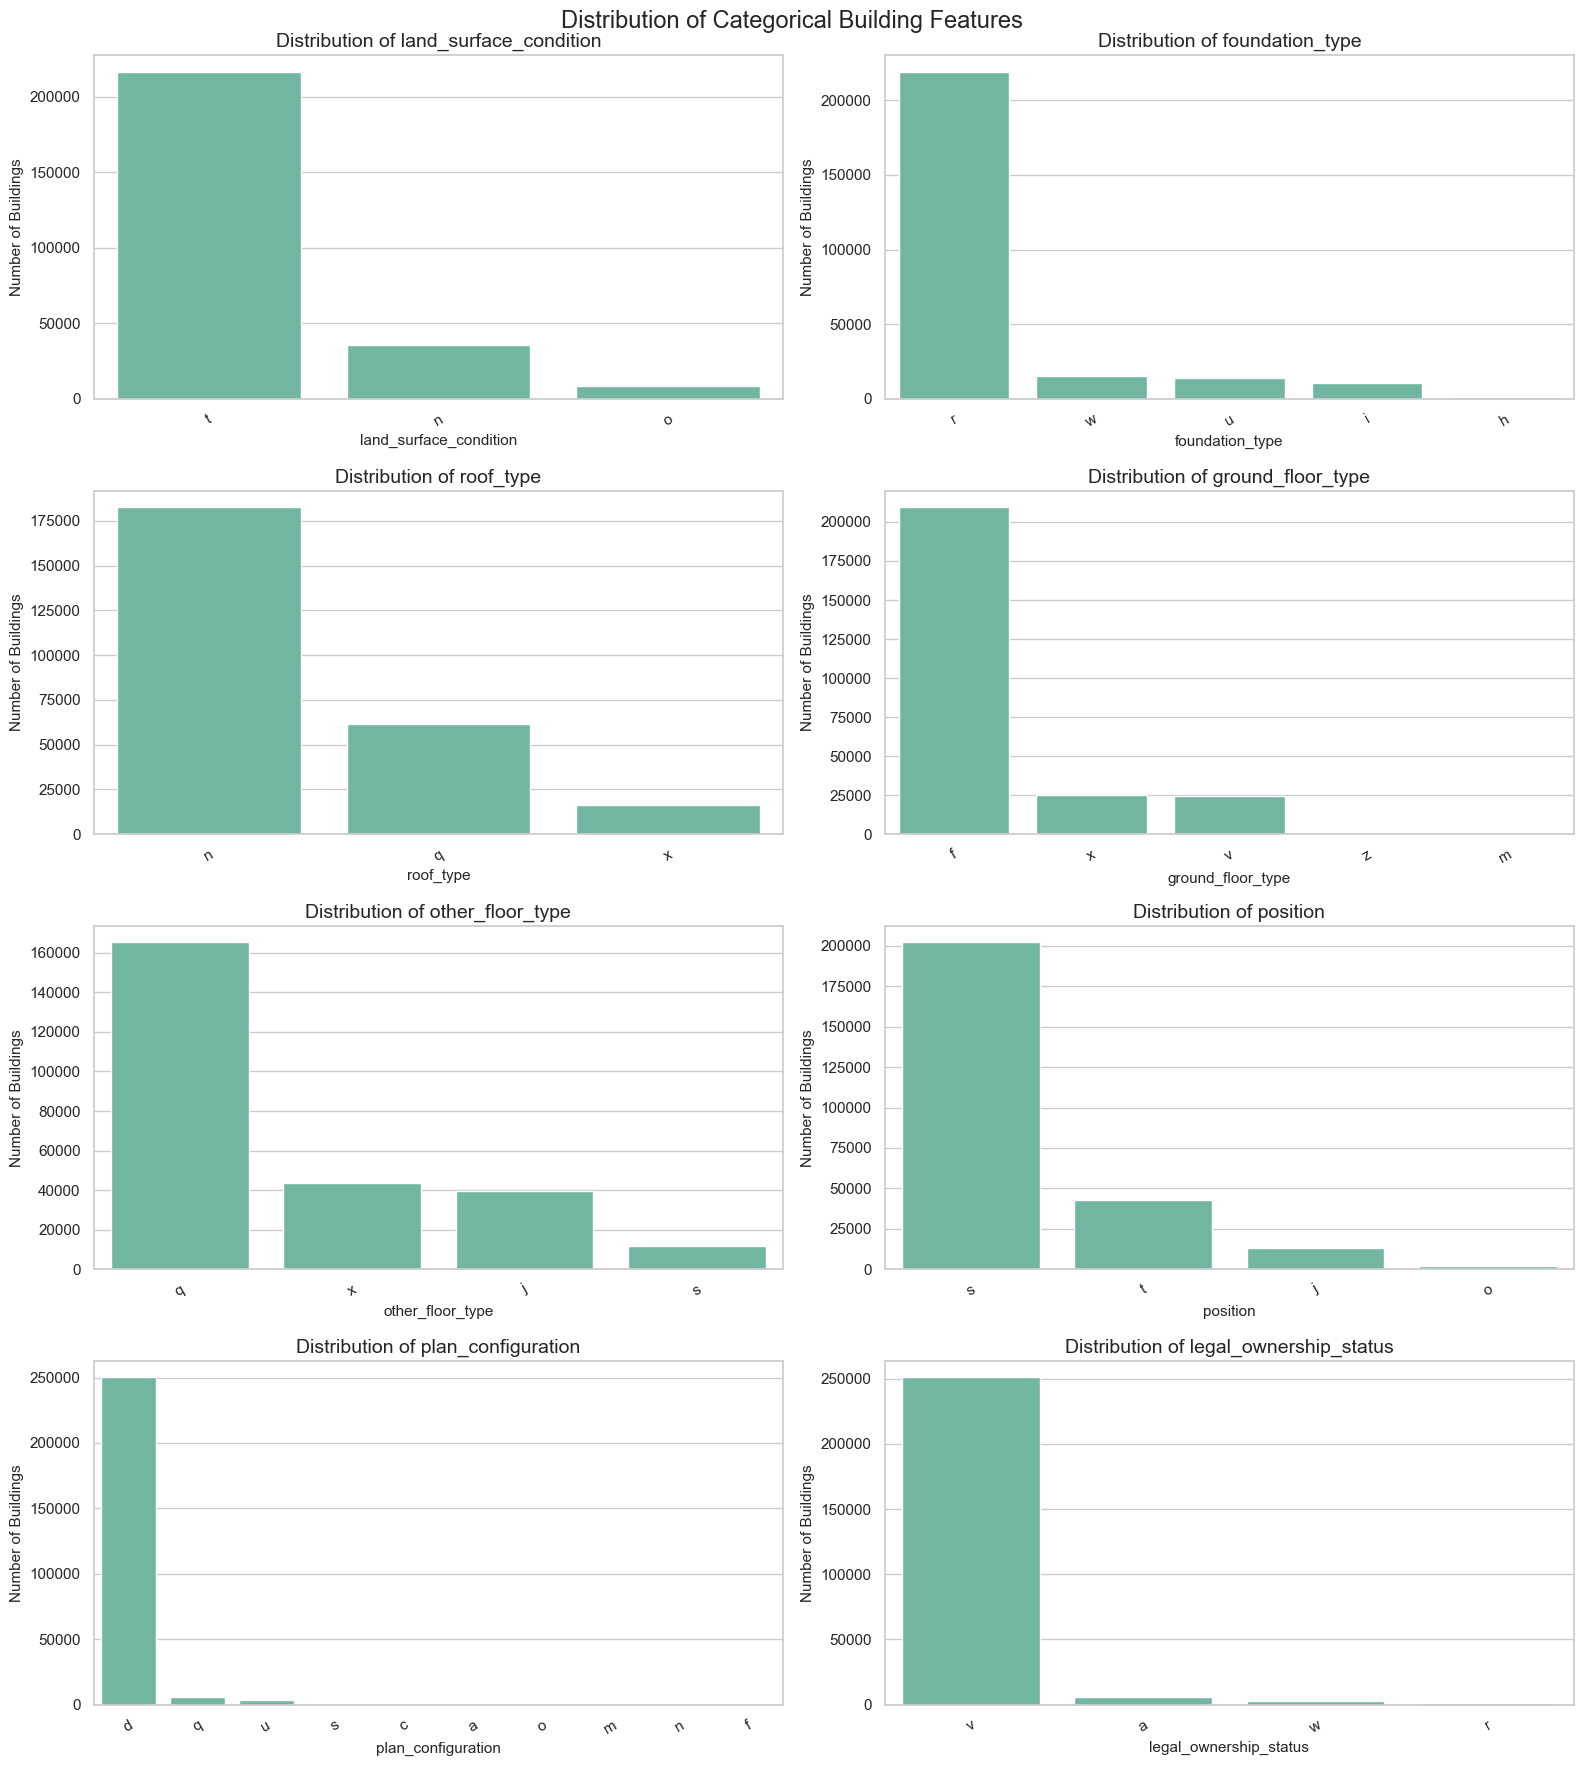

In [18]:
fig, axes = plt.subplots(
    4, 2,
    figsize=(16, 18)
)

for ax, feature in zip(
    axes.flatten(),
    categorical_features
):
    sns.countplot(
        data=df,
        x=feature,
        ax=ax,
        order=df[feature].value_counts().index
    )

    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of Buildings")
    ax.tick_params(axis="x", rotation=30)

plt.suptitle(
    "Distribution of Categorical Building Features",
    fontsize=17
)

plt.tight_layout()
plt.show()

Step 5. Analyze categorical features against damage grade


Damage Distribution by land_surface_condition


damage_grade,1,2,3
land_surface_condition,,,
n,7.19,60.47,32.34
o,7.24,56.61,36.15
t,10.13,56.32,33.55


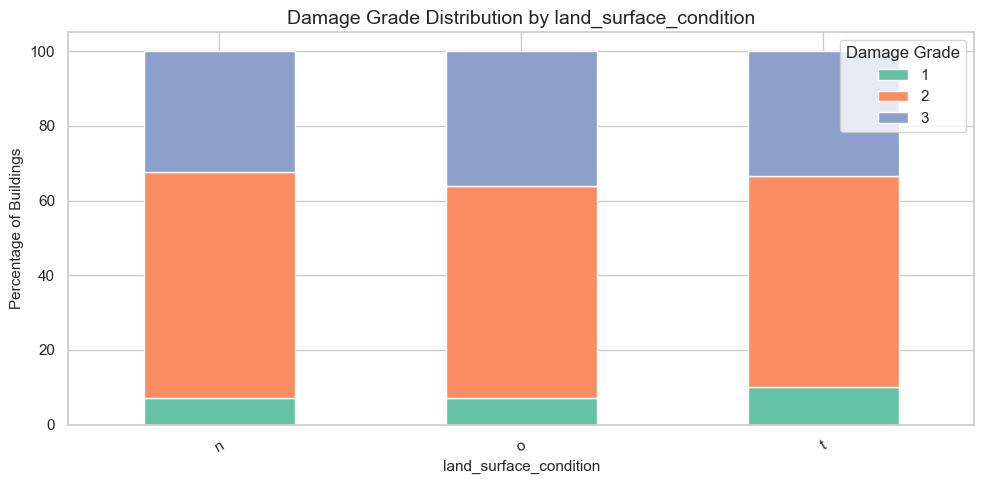


Damage Distribution by foundation_type


damage_grade,1,2,3
foundation_type,,,
h,24.72,39.99,35.29
i,56.75,41.16,2.09
r,4.89,57.26,37.85
u,25.87,59.89,14.24
w,28.79,61.32,9.89


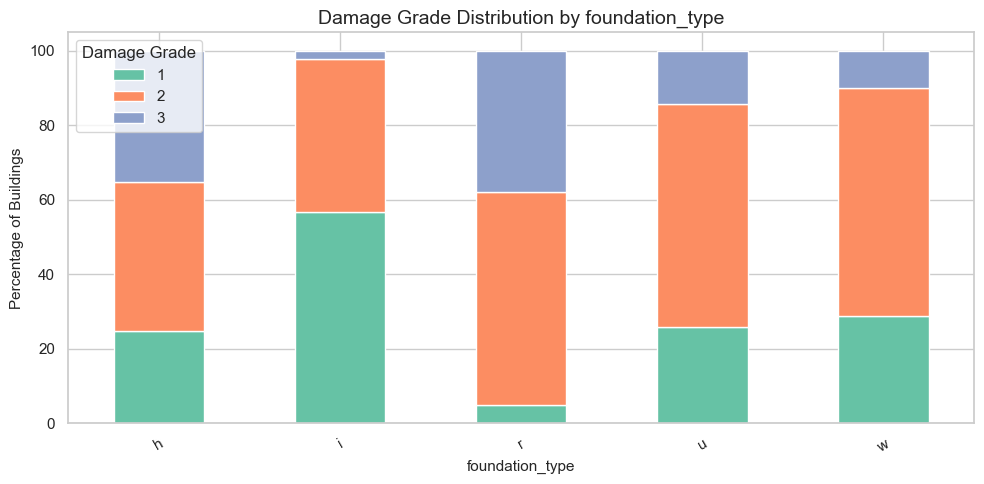


Damage Distribution by roof_type


damage_grade,1,2,3
roof_type,,,
n,7.41,58.22,34.37
q,6.38,55.23,38.39
x,47.28,48.22,4.50


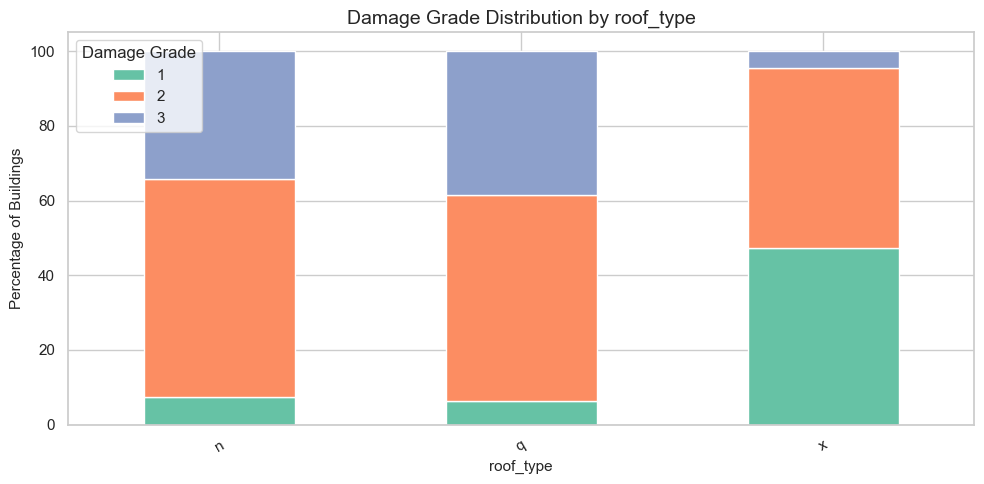


Damage Distribution by ground_floor_type


damage_grade,1,2,3
ground_floor_type,,,
f,5.95,57.19,36.86
m,17.72,67.52,14.76
v,41.92,52.74,5.34
x,8.25,58.43,33.32
z,19.82,52.99,27.19


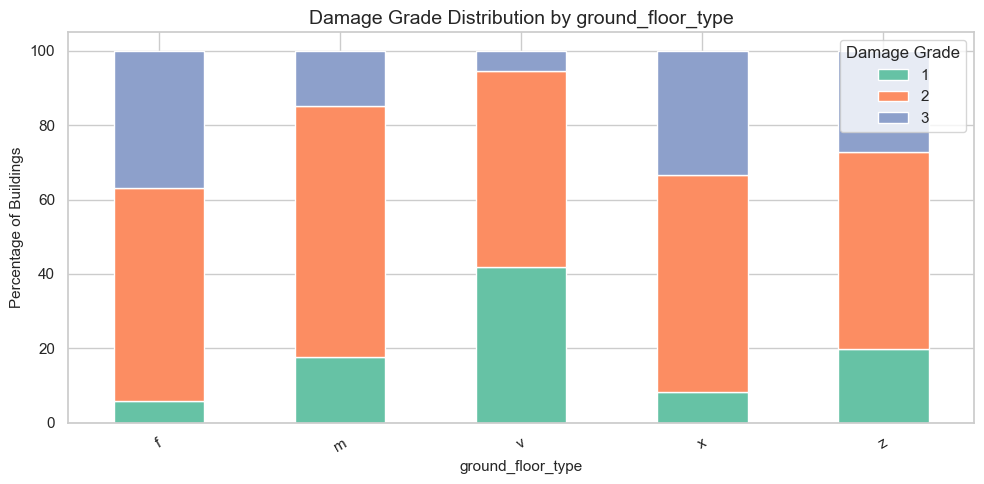


Damage Distribution by other_floor_type


damage_grade,1,2,3
other_floor_type,,,
j,22.30,51.11,26.59
q,4.47,59.49,36.04
s,45.09,49.09,5.83
x,7.89,54.49,37.62


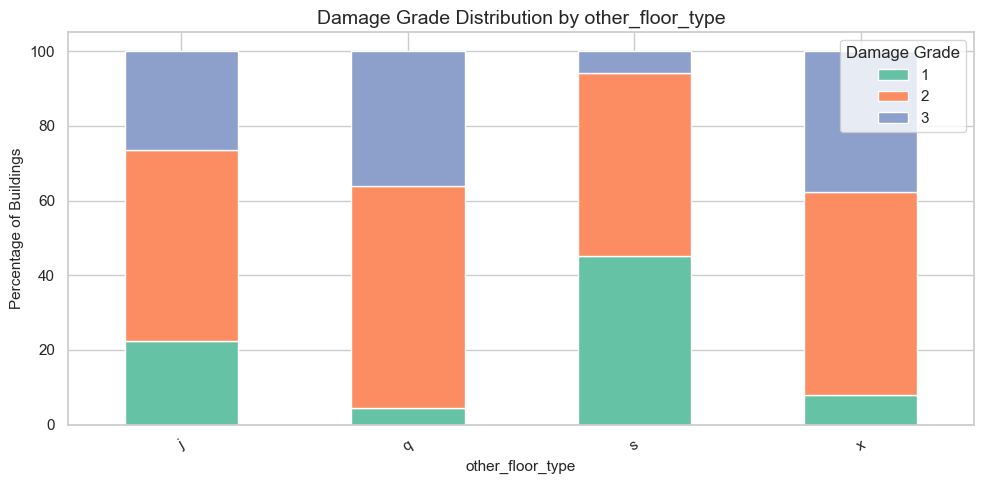


Damage Distribution by position


damage_grade,1,2,3
position,,,
j,12.61,59.47,27.92
o,5.14,68.97,25.89
s,9.83,57.43,32.74
t,8.07,52.92,39.01


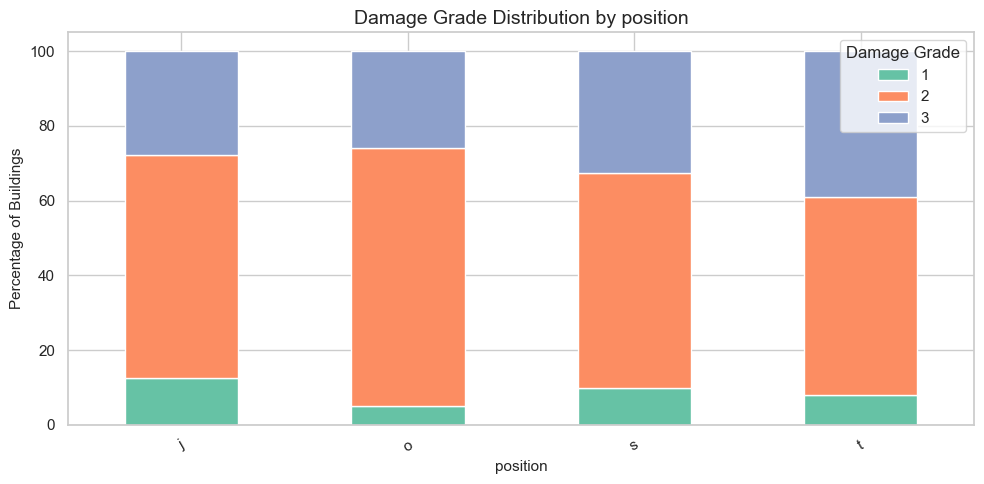


Damage Distribution by plan_configuration


damage_grade,1,2,3
plan_configuration,,,
a,26.19,62.30,11.51
c,26.46,63.38,10.15
d,9.32,56.99,33.69
f,0.00,72.73,27.27
m,17.39,73.91,8.70
n,15.79,52.63,31.58
o,25.16,60.38,14.47
q,13.72,45.41,40.86
s,15.32,64.45,20.23


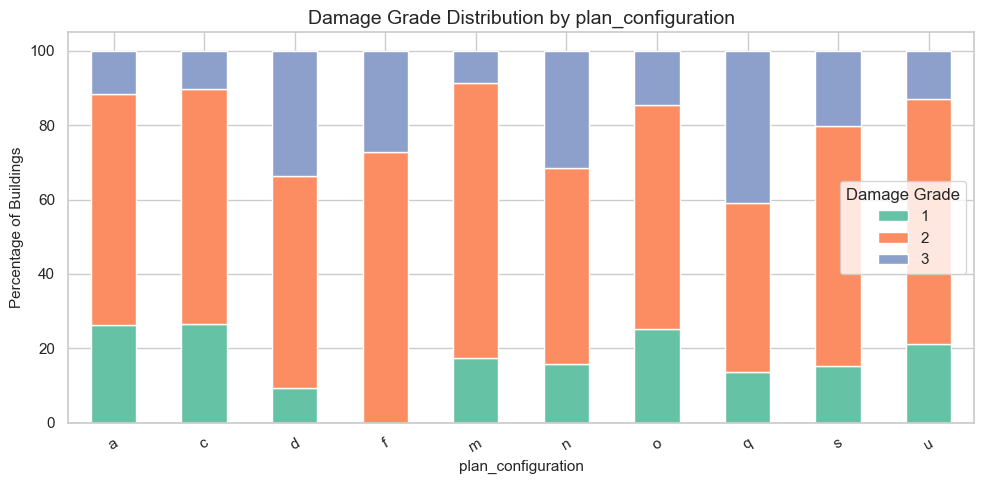


Damage Distribution by legal_ownership_status


damage_grade,1,2,3
legal_ownership_status,,,
a,27.41,55.77,16.82
r,14.46,49.36,36.18
v,9.27,57.05,33.68
w,4.86,48.71,46.43


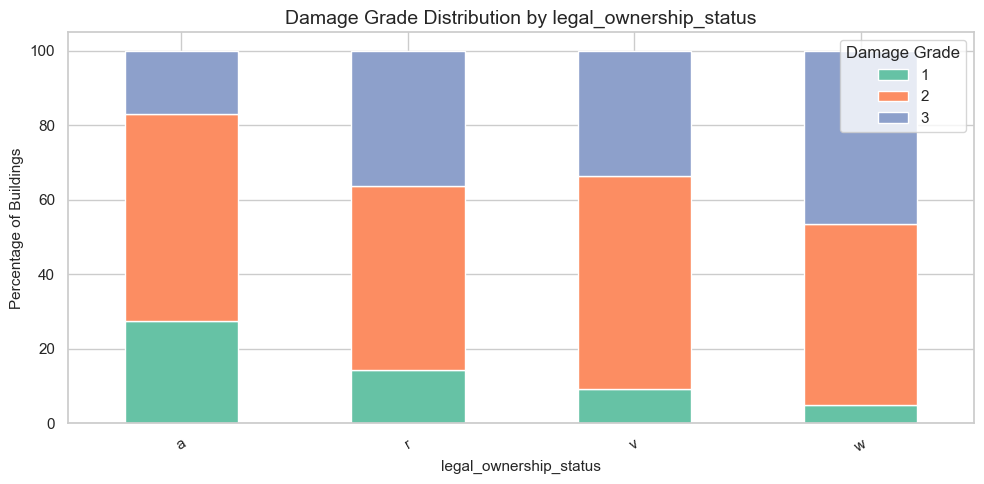

In [19]:
for feature in categorical_features:

    damage_distribution = pd.crosstab(
        df[feature],
        df["damage_grade"],
        normalize="index"
    ) * 100

    print(f"\nDamage Distribution by {feature}")
    display(damage_distribution.round(2))

    damage_distribution.plot(
        kind="bar",
        stacked=True,
        figsize=(10, 5)
    )

    plt.title(f"Damage Grade Distribution by {feature}")
    plt.xlabel(feature)
    plt.ylabel("Percentage of Buildings")
    plt.legend(title="Damage Grade")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

Step 6. Analyze construction materials

In [20]:
superstructure_features = [
    col for col in df.columns
    if col.startswith("has_superstructure_")
]

print("Number of superstructure features:",
      len(superstructure_features))

print(superstructure_features)

Number of superstructure features: 11
['has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_cement_mortar_brick', 'has_superstructure_timber', 'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered', 'has_superstructure_other']


In [21]:
superstructure_summary = pd.DataFrame({
    "Buildings_With_Material": df[superstructure_features].sum(),
    "Percentage": (
        df[superstructure_features].mean() * 100
    )
})

display(
    superstructure_summary.sort_values(
        by="Percentage",
        ascending=False
    ).round(2)
)

,Buildings_With_Material,Percentage
has_superstructure_mud_mortar_stone,198561,76.19
has_superstructure_timber,66450,25.50
has_superstructure_adobe_mud,23101,8.86
has_superstructure_bamboo,22154,8.50
has_superstructure_cement_mortar_brick,19615,7.53
has_superstructure_mud_mortar_brick,17761,6.82
has_superstructure_rc_non_engineered,11099,4.26
has_superstructure_stone_flag,8947,3.43
has_superstructure_cement_mortar_stone,4752,1.82
has_superstructure_rc_engineered,4133,1.59


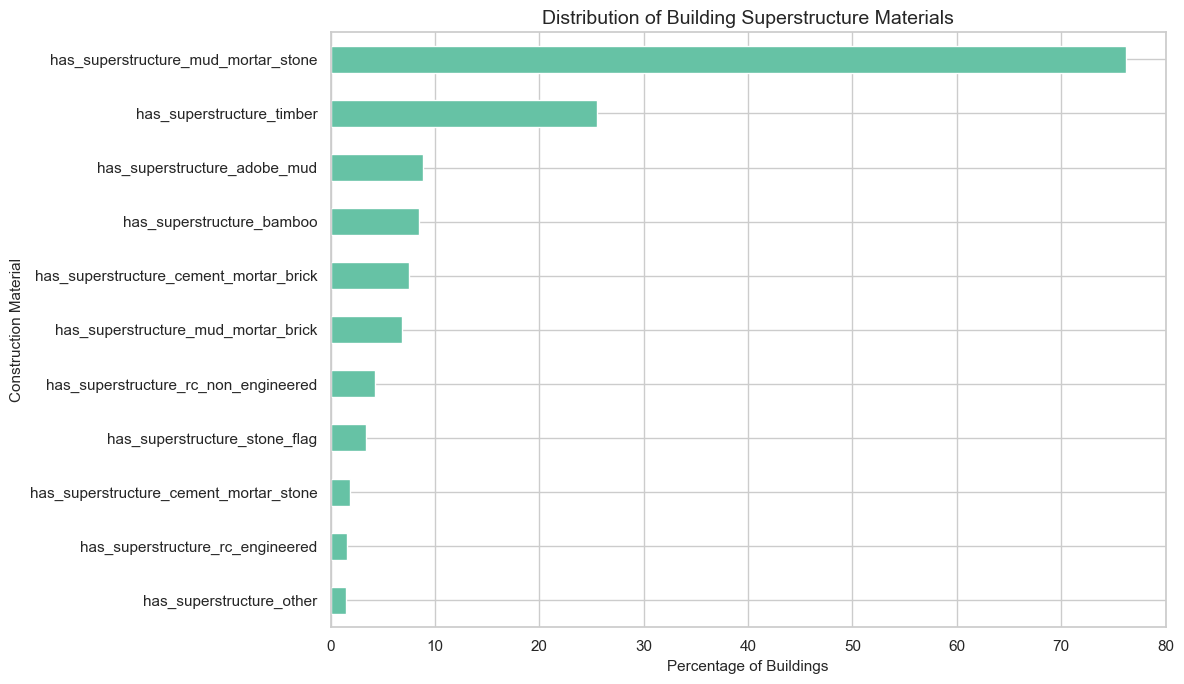

In [22]:
superstructure_summary.sort_values(
    by="Percentage"
)["Percentage"].plot(
    kind="barh",
    figsize=(12, 7)
)

plt.title("Distribution of Building Superstructure Materials")
plt.xlabel("Percentage of Buildings")
plt.ylabel("Construction Material")
plt.tight_layout()
plt.show()

In [23]:
material_damage = df.groupby(
    "damage_grade"
)[superstructure_features].mean().T * 100

display(material_damage.round(2))

damage_grade,1,2,3
has_superstructure_adobe_mud,2.36,9.38,9.87
has_superstructure_mud_mortar_stone,34.87,76.86,86.97
has_superstructure_stone_flag,0.72,3.06,4.85
has_superstructure_cement_mortar_stone,3.30,2.19,0.77
has_superstructure_mud_mortar_brick,2.48,7.89,6.24
has_superstructure_cement_mortar_brick,28.28,7.70,1.25
has_superstructure_timber,30.42,27.11,21.35
has_superstructure_bamboo,11.30,9.44,6.09
has_superstructure_rc_non_engineered,15.35,3.93,1.62
has_superstructure_rc_engineered,10.57,0.95,0.09


Step 7. Geographic analysis

In [24]:
geo_features = [
    "geo_level_1_id",
    "geo_level_2_id",
    "geo_level_3_id"
]

In [25]:
for feature in geo_features:

    print(f"\n{feature}")
    print("Unique regions:", df[feature].nunique())
    print("Most common regions:")
    display(df[feature].value_counts().head(10))


geo_level_1_id
Unique regions: 31
Most common regions:


geo_level_1_id
6     24381
26    22615
10    22079
17    21813
8     19080
7     18994
20    17216
21    14889
4     14568
27    12532
Name: count, dtype: int64


geo_level_2_id
Unique regions: 1414
Most common regions:


geo_level_2_id
39      4038
158     2520
181     2080
1387    2040
157     1897
363     1760
463     1740
673     1704
533     1684
883     1626
Name: count, dtype: int64


geo_level_3_id
Unique regions: 11595
Most common regions:


geo_level_3_id
633      651
9133     647
621      530
11246    470
2005     466
11440    455
7723     443
9229     381
2452     349
12258    312
Name: count, dtype: int64

In [26]:
geo_damage = pd.crosstab(
    df["geo_level_1_id"],
    df["damage_grade"],
    normalize="index"
) * 100

geo_damage["Total_Buildings"] = df.groupby(
    "geo_level_1_id"
).size()

display(
    geo_damage.sort_values(
        by=3,
        ascending=False
    ).head(15).round(2)
)

damage_grade,1,2,3,Total_Buildings
geo_level_1_id,,,,
17,1.31,17.94,80.75,21813
18,2.26,24.65,73.10,3189
21,2.16,39.34,58.50,14889
8,3.43,44.62,51.95,19080
27,3.71,47.93,48.36,12532
28,0.00,59.25,40.75,265
10,5.48,54.83,39.68,22079
11,4.70,56.84,38.47,8220
3,3.25,60.34,36.41,7540


Phase 4: Data Preprocessing and Feature Engineering

Step 1. Separate features and target variable

## 8. Data Preprocessing and Feature Engineering

This phase prepares the earthquake building dataset for machine learning.

The target variable is damage_grade, which represents three levels of building damage.

The building_id column is excluded from predictive features because it is only a unique identifier.

The geographical identifiers are treated as categorical variables because their numerical values do not represent measurable quantities.

The dataset will be divided into training and testing sets before fitting preprocessing transformations to avoid data leakage.

In [27]:
# Separate input features and target variable

X = df.drop(columns=["damage_grade", "building_id"])
y = df["damage_grade"]

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nTarget classes:")
print(sorted(y.unique()))

print("\nTarget distribution:")
print(y.value_counts().sort_index())

Feature dataset shape: (260601, 38)
Target dataset shape: (260601,)

Target classes:
[np.int64(1), np.int64(2), np.int64(3)]

Target distribution:
damage_grade
1     25124
2    148259
3     87218
Name: count, dtype: int64


In [28]:
print("Is building_id present in X?", "building_id" in X.columns)
print("Is damage_grade present in X?", "damage_grade" in X.columns)

print("\nFeature columns:")
print(X.columns.tolist())

Is building_id present in X? False
Is damage_grade present in X? False

Feature columns:
['geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id', 'count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_cement_mortar_brick', 'has_superstructure_timber', 'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered', 'has_superstructure_other', 'legal_ownership_status', 'count_families', 'has_secondary_use', 'has_secondary_use_agriculture', 'has_secondary_use_hotel', 'has_secondary_use_rental', 'has_secondary_use_institution', 'has_secondary_use_school', 'has_secondary_use_industry', 'has_secondary_use_h

Step 2. Identify numerical and categorical features

In [29]:
# Identify geographical features
geo_features = [
    "geo_level_1_id",
    "geo_level_2_id",
    "geo_level_3_id"
]

# Identify categorical features from object columns
object_features = X.select_dtypes(include=["object"]).columns.tolist()

# Combine object and geographical features
categorical_features = object_features + geo_features

# Remaining features are treated as numerical
numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

print("Number of categorical features:", len(categorical_features))
print("Number of numerical features:", len(numerical_features))

print("\nCategorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Number of categorical features: 11
Number of numerical features: 27

Categorical features:
['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'legal_ownership_status', 'geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id']

Numerical features:
['count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_cement_mortar_brick', 'has_superstructure_timber', 'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered', 'has_superstructure_other', 'count_families', 'has_secondary_use', 'has_secondary_use_agriculture', 'has_secondary_use_hotel', 'has_secondary_use_rental', 'has_secondary_use_institution', 'has_secondary_use_school', 'has_secondary_use_industr

In [30]:
# Check that every feature is assigned exactly once

all_features = categorical_features + numerical_features

print("Total classified features:", len(all_features))
print("Total original features:", X.shape[1])

print("No duplicate assignments:", len(all_features) == len(set(all_features)))
print("All features classified:", set(all_features) == set(X.columns))

Total classified features: 38
Total original features: 38
No duplicate assignments: True
All features classified: True


In [31]:
print("Geographical Feature Cardinality\n")

for feature in geo_features:
    print(f"{feature}:")
    print("Unique values:", X[feature].nunique())
    print("Data type:", X[feature].dtype)
    print("-" * 40)

Geographical Feature Cardinality

geo_level_1_id:
Unique values: 31
Data type: int64
----------------------------------------
geo_level_2_id:
Unique values: 1414
Data type: int64
----------------------------------------
geo_level_3_id:
Unique values: 11595
Data type: int64
----------------------------------------


Step 3. Split the dataset into training and testing sets

## 9. Train-Test Split

The dataset is divided into training and testing sets using an 80:20 ratio.

The training set is used to train machine learning models, while the testing set is reserved for evaluating model performance on unseen data.

Stratified sampling is applied to maintain the original distribution of the three damage grades in both sets.

A fixed random state is used to ensure reproducibility.

In [32]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training and Testing Split Completed!")

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training and Testing Split Completed!

Training feature shape: (208480, 38)
Testing feature shape: (52121, 38)

Training target shape: (208480,)
Testing target shape: (52121,)


In [33]:
# Compare target distribution before and after splitting

distribution_check = pd.DataFrame({
    "Original (%)": y.value_counts(normalize=True).sort_index() * 100,
    "Training (%)": y_train.value_counts(normalize=True).sort_index() * 100,
    "Testing (%)": y_test.value_counts(normalize=True).sort_index() * 100
})

distribution_check.index.name = "Damage Grade"

display(distribution_check.round(2))

,Original (%),Training (%),Testing (%)
Damage Grade,,,
1,9.64,9.64,9.64
2,56.89,56.89,56.89
3,33.47,33.47,33.47


In [34]:
print("Total original records:", len(X))
print("Total training records:", len(X_train))
print("Total testing records:", len(X_test))

print("\nTraining + Testing equals Original:",
      len(X_train) + len(X_test) == len(X))

print("Training and testing indexes overlap:",
      len(set(X_train.index).intersection(set(X_test.index))) > 0)

Total original records: 260601
Total training records: 208480
Total testing records: 52121

Training + Testing equals Original: True
Training and testing indexes overlap: False


Step 4. Analyse geographical feature frequencies

In [35]:
# Analyse geographical category frequencies using training data only

geo_features = [
    "geo_level_1_id",
    "geo_level_2_id",
    "geo_level_3_id"
]

for feature in geo_features:

    frequency = X_train[feature].value_counts()

    print(f"\nAnalysis of {feature}")
    print("-" * 45)

    print("Total unique categories:", frequency.size)
    print("Categories appearing 50 or more times:", (frequency >= 50).sum())
    print("Categories appearing fewer than 50 times:", (frequency < 50).sum())
    print("Minimum frequency:", frequency.min())
    print("Maximum frequency:", frequency.max())
    print("Median frequency:", frequency.median())


Analysis of geo_level_1_id
---------------------------------------------
Total unique categories: 31
Categories appearing 50 or more times: 31
Categories appearing fewer than 50 times: 0
Minimum frequency: 221
Maximum frequency: 19518
Median frequency: 3436.0

Analysis of geo_level_2_id
---------------------------------------------
Total unique categories: 1409
Categories appearing 50 or more times: 876
Categories appearing fewer than 50 times: 533
Minimum frequency: 1
Maximum frequency: 3203
Median frequency: 97.0

Analysis of geo_level_3_id
---------------------------------------------
Total unique categories: 11380
Categories appearing 50 or more times: 767
Categories appearing fewer than 50 times: 10613
Minimum frequency: 1
Maximum frequency: 516
Median frequency: 12.0


In [36]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.6.1


Step 5. Build the preprocessing pipeline

## 10. Feature Encoding and Preprocessing

Categorical features are converted into numerical representations using One-Hot Encoding.

Geographical identifiers are encoded separately using One-Hot Encoding with a minimum category frequency of 50. This groups rare geographical categories into an infrequent category.

Numerical and binary features are retained without scaling at this stage.

The preprocessing transformations are fitted only on the training dataset and then applied to the testing dataset. This prevents data leakage.

In [37]:
# Separate ordinary categorical and geographical features

geo_features = [
    "geo_level_1_id",
    "geo_level_2_id",
    "geo_level_3_id"
]

ordinary_categorical_features = [
    col for col in categorical_features
    if col not in geo_features
]

print("Ordinary categorical features:", len(ordinary_categorical_features))
print("Geographical features:", len(geo_features))
print("Numerical features:", len(numerical_features))

Ordinary categorical features: 8
Geographical features: 3
Numerical features: 27


In [38]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# One-hot encoding for ordinary categorical features
ordinary_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True
)

# One-hot encoding for geographical features
geo_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=50,
    sparse_output=True
)

# Combine all preprocessing operations
preprocessor = ColumnTransformer(
    transformers=[
        ("ordinary_cat", ordinary_encoder, ordinary_categorical_features),
        ("geo_cat", geo_encoder, geo_features),
        ("numerical", "passthrough", numerical_features)
    ],
    remainder="drop",
    sparse_threshold=1.0
)

print("Preprocessing transformer created successfully!")

Preprocessing transformer created successfully!


In [39]:
# Fit preprocessing using training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the same fitted preprocessing
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")

print("\nOriginal training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

Preprocessing completed successfully!

Original training shape: (208480, 38)
Processed training shape: (208480, 1741)

Original testing shape: (52121, 38)
Processed testing shape: (52121, 1741)


In [40]:
from scipy import sparse

print("Training data is sparse:", sparse.issparse(X_train_processed))
print("Testing data is sparse:", sparse.issparse(X_test_processed))

print("\nTraining data contains NaN:", 
      np.isnan(X_train_processed.data).any()
      if sparse.issparse(X_train_processed)
      else np.isnan(X_train_processed).any())

print("Testing data contains NaN:",
      np.isnan(X_test_processed.data).any()
      if sparse.issparse(X_test_processed)
      else np.isnan(X_test_processed).any())

print("\nTraining and testing feature dimensions match:",
      X_train_processed.shape[1] == X_test_processed.shape[1])

Training data is sparse: True
Testing data is sparse: True

Training data contains NaN: False
Testing data contains NaN: False

Training and testing feature dimensions match: True


In [41]:
feature_names = preprocessor.get_feature_names_out()

print("Total processed features:", len(feature_names))

print("\nFirst 30 processed feature names:")
print(feature_names[:30])

Total processed features: 1741

First 30 processed feature names:
['ordinary_cat__land_surface_condition_n'
 'ordinary_cat__land_surface_condition_o'
 'ordinary_cat__land_surface_condition_t'
 'ordinary_cat__foundation_type_h' 'ordinary_cat__foundation_type_i'
 'ordinary_cat__foundation_type_r' 'ordinary_cat__foundation_type_u'
 'ordinary_cat__foundation_type_w' 'ordinary_cat__roof_type_n'
 'ordinary_cat__roof_type_q' 'ordinary_cat__roof_type_x'
 'ordinary_cat__ground_floor_type_f' 'ordinary_cat__ground_floor_type_m'
 'ordinary_cat__ground_floor_type_v' 'ordinary_cat__ground_floor_type_x'
 'ordinary_cat__ground_floor_type_z' 'ordinary_cat__other_floor_type_j'
 'ordinary_cat__other_floor_type_q' 'ordinary_cat__other_floor_type_s'
 'ordinary_cat__other_floor_type_x' 'ordinary_cat__position_j'
 'ordinary_cat__position_o' 'ordinary_cat__position_s'
 'ordinary_cat__position_t' 'ordinary_cat__plan_configuration_a'
 'ordinary_cat__plan_configuration_c' 'ordinary_cat__plan_configuration_d'
 'o

Phase 5: Machine Learning Model Development

Step 1. Establish a baseline model

## 11. Machine Learning Model Development

In this phase, multiple machine learning algorithms are trained to predict building damage grades.

A baseline model is first created using DummyClassifier to establish a reference performance.

The performance of subsequent models will be compared against this baseline.

Evaluation will include accuracy, precision, recall, macro F1-score, weighted F1-score, and Mean Absolute Error.

Since damage_grade is an ordinal target, Mean Absolute Error will also help measure how far predictions are from the actual damage grades.

In [42]:
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    classification_report,
    confusion_matrix
)

print("Model evaluation libraries imported successfully!")

Model evaluation libraries imported successfully!


In [43]:
# Create baseline model

baseline_model = DummyClassifier(
    strategy="most_frequent"
)

# Train baseline model
baseline_model.fit(
    X_train_processed,
    y_train
)

# Generate predictions
baseline_predictions = baseline_model.predict(
    X_test_processed
)

print("Baseline model training completed!")

Baseline model training completed!


In [44]:
baseline_accuracy = accuracy_score(
    y_test, baseline_predictions
)

baseline_precision = precision_score(
    y_test, baseline_predictions,
    average="weighted",
    zero_division=0
)

baseline_recall = recall_score(
    y_test, baseline_predictions,
    average="weighted",
    zero_division=0
)

baseline_macro_f1 = f1_score(
    y_test, baseline_predictions,
    average="macro",
    zero_division=0
)

baseline_weighted_f1 = f1_score(
    y_test, baseline_predictions,
    average="weighted",
    zero_division=0
)

baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

print("BASELINE MODEL PERFORMANCE")
print("-" * 40)

print(f"Accuracy:          {baseline_accuracy:.4f}")
print(f"Precision:         {baseline_precision:.4f}")
print(f"Recall:            {baseline_recall:.4f}")
print(f"Macro F1-score:    {baseline_macro_f1:.4f}")
print(f"Weighted F1-score: {baseline_weighted_f1:.4f}")
print(f"Mean Absolute Error: {baseline_mae:.4f}")

BASELINE MODEL PERFORMANCE
----------------------------------------
Accuracy:          0.5689
Precision:         0.3237
Recall:            0.5689
Macro F1-score:    0.2417
Weighted F1-score: 0.4126
Mean Absolute Error: 0.4311


In [45]:
print(
    classification_report(
        y_test,
        baseline_predictions,
        labels=[1, 2, 3],
        target_names=[
            "Grade 1 - Low Damage",
            "Grade 2 - Medium Damage",
            "Grade 3 - Severe Damage"
        ],
        zero_division=0
    )
)

                         precision    recall  f1-score   support

   Grade 1 - Low Damage       0.00      0.00      0.00      5025
Grade 2 - Medium Damage       0.57      1.00      0.73     29652
Grade 3 - Severe Damage       0.00      0.00      0.00     17444

               accuracy                           0.57     52121
              macro avg       0.19      0.33      0.24     52121
           weighted avg       0.32      0.57      0.41     52121



Step 2. Train Model 1 – Decision Tree Classifier

## 12. Model 1 - Decision Tree Classifier

A Decision Tree Classifier is used to predict earthquake damage grades.

The algorithm learns decision rules from building characteristics and divides observations into different damage categories.

Class weighting is applied to address the imbalance in the target variable.

The model is evaluated using accuracy, precision, recall, macro F1-score, weighted F1-score, and Mean Absolute Error.

In [46]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(
    max_depth=20,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42
)

print("Decision Tree model created successfully!")

Decision Tree model created successfully!


In [47]:
decision_tree_model.fit(
    X_train_processed,
    y_train
)

print("Decision Tree model training completed!")

Decision Tree model training completed!


In [48]:
decision_tree_predictions = decision_tree_model.predict(
    X_test_processed
)

print("Predictions generated successfully!")

print("First 20 predictions:")
print(decision_tree_predictions[:20])

Predictions generated successfully!
First 20 predictions:
[2 2 1 2 3 2 3 1 3 2 1 2 3 1 3 1 1 3 1 2]


In [49]:
dt_accuracy = accuracy_score(y_test, decision_tree_predictions)

dt_precision = precision_score(
    y_test, decision_tree_predictions,
    average="weighted", zero_division=0
)

dt_recall = recall_score(
    y_test, decision_tree_predictions,
    average="weighted", zero_division=0
)

dt_macro_f1 = f1_score(
    y_test, decision_tree_predictions,
    average="macro", zero_division=0
)

dt_weighted_f1 = f1_score(
    y_test, decision_tree_predictions,
    average="weighted", zero_division=0
)

dt_mae = mean_absolute_error(y_test, decision_tree_predictions)

print("DECISION TREE MODEL PERFORMANCE")
print("-" * 45)

print(f"Accuracy:           {dt_accuracy:.4f}")
print(f"Precision:          {dt_precision:.4f}")
print(f"Recall:             {dt_recall:.4f}")
print(f"Macro F1-score:     {dt_macro_f1:.4f}")
print(f"Weighted F1-score:  {dt_weighted_f1:.4f}")
print(f"Mean Absolute Error: {dt_mae:.4f}")

DECISION TREE MODEL PERFORMANCE
---------------------------------------------
Accuracy:           0.6447
Precision:          0.6832
Recall:             0.6447
Macro F1-score:     0.6168
Weighted F1-score:  0.6518
Mean Absolute Error: 0.3720


In [50]:
print(
    classification_report(
        y_test,
        decision_tree_predictions,
        labels=[1, 2, 3],
        target_names=[
            "Grade 1 - Low Damage",
            "Grade 2 - Medium Damage",
            "Grade 3 - Severe Damage"
        ],
        zero_division=0
    )
)

                         precision    recall  f1-score   support

   Grade 1 - Low Damage       0.39      0.78      0.52      5025
Grade 2 - Medium Damage       0.76      0.59      0.67     29652
Grade 3 - Severe Damage       0.64      0.69      0.67     17444

               accuracy                           0.64     52121
              macro avg       0.60      0.69      0.62     52121
           weighted avg       0.68      0.64      0.65     52121



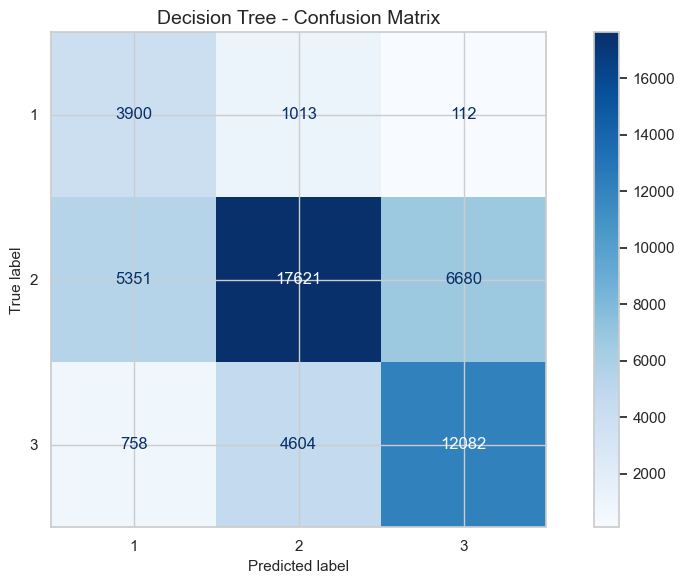

In [51]:
cm_dt = confusion_matrix(
    y_test,
    decision_tree_predictions,
    labels=[1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=[1, 2, 3]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()

### Decision Tree Model - Observations

The Decision Tree Classifier achieved an accuracy of 64.47% and a macro F1-score of 0.6168.

Class weighting helped the model identify all three damage grades, including the minority Grade 1 class.

The model achieved a recall of 0.78 for Grade 1, 0.59 for Grade 2, and 0.69 for Grade 3.

However, Grade 1 precision was relatively low at 0.39, indicating that some buildings were incorrectly classified as low damage.

Compared with the baseline model, the Decision Tree achieved a substantial improvement in macro F1-score and a lower Mean Absolute Error.

Further model comparisons are required before selecting the final model.

Step 3. Train Model 2 – Random Forest Classifier

## 13. Model 2 - Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple decision trees to improve predictive performance.

Each tree learns from the training data, and the final prediction is determined through majority voting.

Class weighting is used to address the imbalance in the damage grade distribution.

The model is evaluated using the same metrics as the previous models.

In [52]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_split=20,
    min_samples_leaf=10,
    max_features="sqrt",
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [53]:
random_forest_model.fit(
    X_train_processed,
    y_train
)

print("Random Forest model training completed!")

Random Forest model training completed!


In [54]:
rf_predictions = random_forest_model.predict(
    X_test_processed
)

print("Random Forest predictions generated successfully!")
print("First 20 predictions:")
print(rf_predictions[:20])

Random Forest predictions generated successfully!
First 20 predictions:
[3 1 1 2 3 2 3 1 3 2 3 2 3 1 3 2 2 3 1 2]


In [55]:
rf_accuracy = accuracy_score(y_test, rf_predictions)

rf_precision = precision_score(
    y_test, rf_predictions,
    average="weighted", zero_division=0
)

rf_recall = recall_score(
    y_test, rf_predictions,
    average="weighted", zero_division=0
)

rf_macro_f1 = f1_score(
    y_test, rf_predictions,
    average="macro", zero_division=0
)

rf_weighted_f1 = f1_score(
    y_test, rf_predictions,
    average="weighted", zero_division=0
)

rf_mae = mean_absolute_error(y_test, rf_predictions)

print("RANDOM FOREST MODEL PERFORMANCE")
print("-" * 45)

print(f"Accuracy:           {rf_accuracy:.4f}")
print(f"Precision:          {rf_precision:.4f}")
print(f"Recall:             {rf_recall:.4f}")
print(f"Macro F1-score:     {rf_macro_f1:.4f}")
print(f"Weighted F1-score:  {rf_weighted_f1:.4f}")
print(f"Mean Absolute Error: {rf_mae:.4f}")

RANDOM FOREST MODEL PERFORMANCE
---------------------------------------------
Accuracy:           0.6191
Precision:          0.6708
Recall:             0.6191
Macro F1-score:     0.5982
Weighted F1-score:  0.6214
Mean Absolute Error: 0.3979


In [56]:
print(
    classification_report(
        y_test,
        rf_predictions,
        labels=[1, 2, 3],
        target_names=[
            "Grade 1 - Low Damage",
            "Grade 2 - Medium Damage",
            "Grade 3 - Severe Damage"
        ],
        zero_division=0
    )
)

                         precision    recall  f1-score   support

   Grade 1 - Low Damage       0.39      0.76      0.52      5025
Grade 2 - Medium Damage       0.77      0.52      0.62     29652
Grade 3 - Severe Damage       0.58      0.76      0.66     17444

               accuracy                           0.62     52121
              macro avg       0.58      0.68      0.60     52121
           weighted avg       0.67      0.62      0.62     52121



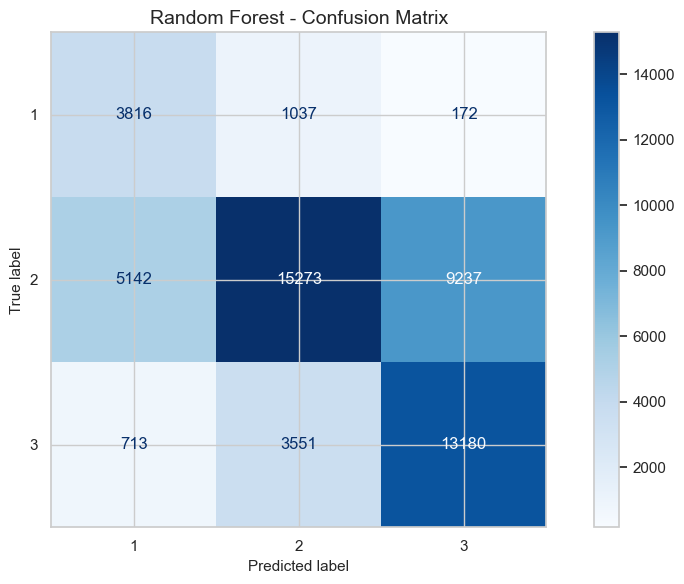

In [57]:
cm_rf = confusion_matrix(
    y_test,
    rf_predictions,
    labels=[1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=[1, 2, 3]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

Step 4. Model evaluation strategy improvement

In [58]:
from sklearn.base import clone

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=42,
    stratify=y_train
)

print("Model fitting data:", X_fit.shape)
print("Validation data:", X_val.shape)

print("\nTarget distribution in validation data:")
print((y_val.value_counts(normalize=True).sort_index() * 100).round(2))

Model fitting data: (177208, 38)
Validation data: (31272, 38)

Target distribution in validation data:
damage_grade
1     9.64
2    56.89
3    33.47
Name: proportion, dtype: float64


In [59]:
# Create an independent copy of the preprocessing pipeline
validation_preprocessor = clone(preprocessor)

# Fit only on model fitting data
X_fit_processed = validation_preprocessor.fit_transform(X_fit)

# Transform validation data
X_val_processed = validation_preprocessor.transform(X_val)

print("Validation preprocessing completed!")

print("Training matrix:", X_fit_processed.shape)
print("Validation matrix:", X_val_processed.shape)

Validation preprocessing completed!
Training matrix: (177208, 1473)
Validation matrix: (31272, 1473)


In [60]:
print("Fit records:", len(X_fit))
print("Validation records:", len(X_val))

print("Total equals original training data:",
      len(X_fit) + len(X_val) == len(X_train))

print("No index overlap:",
      len(set(X_fit.index).intersection(set(X_val.index))) == 0)

Fit records: 177208
Validation records: 31272
Total equals original training data: True
No index overlap: True


Phase 5 – Step 5: Model 3 – Extra Trees Classifier

## 14. Model 3 - Extra Trees Classifier

Extra Trees (Extremely Randomized Trees) is an ensemble learning algorithm that combines multiple randomized decision trees.

Unlike Random Forest, Extra Trees introduces additional randomness when selecting split points.

This model is evaluated to determine whether increased randomization improves earthquake damage classification.

Class weighting is used to address the imbalance in the target variable.

In [61]:
from sklearn.ensemble import ExtraTreesClassifier

extra_trees_model = ExtraTreesClassifier(
    n_estimators=100,
    max_depth=25,
    min_samples_split=20,
    min_samples_leaf=10,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print("Extra Trees model created successfully!")

Extra Trees model created successfully!


In [62]:
extra_trees_model.fit(
    X_fit_processed,
    y_fit
)

print("Extra Trees model training completed!")

Extra Trees model training completed!


In [63]:
et_predictions = extra_trees_model.predict(
    X_val_processed
)

print("Extra Trees predictions generated successfully!")

print("First 20 predictions:")
print(et_predictions[:20])

Extra Trees predictions generated successfully!
First 20 predictions:
[2 3 3 2 2 2 2 3 2 1 2 3 2 3 3 3 2 1 2 3]


In [64]:
et_accuracy = accuracy_score(y_val, et_predictions)

et_precision = precision_score(
    y_val, et_predictions,
    average="weighted",
    zero_division=0
)

et_recall = recall_score(
    y_val, et_predictions,
    average="weighted",
    zero_division=0
)

et_macro_f1 = f1_score(
    y_val, et_predictions,
    average="macro",
    zero_division=0
)

et_weighted_f1 = f1_score(
    y_val, et_predictions,
    average="weighted",
    zero_division=0
)

et_mae = mean_absolute_error(y_val, et_predictions)

print("EXTRA TREES MODEL PERFORMANCE")
print("-" * 45)

print(f"Accuracy:            {et_accuracy:.4f}")
print(f"Precision:           {et_precision:.4f}")
print(f"Recall:              {et_recall:.4f}")
print(f"Macro F1-score:      {et_macro_f1:.4f}")
print(f"Weighted F1-score:   {et_weighted_f1:.4f}")
print(f"Mean Absolute Error: {et_mae:.4f}")

EXTRA TREES MODEL PERFORMANCE
---------------------------------------------
Accuracy:            0.6253
Precision:           0.6731
Recall:              0.6253
Macro F1-score:      0.6026
Weighted F1-score:   0.6291
Mean Absolute Error: 0.3905


In [65]:
print(
    classification_report(
        y_val,
        et_predictions,
        labels=[1, 2, 3],
        target_names=[
            "Grade 1 - Low Damage",
            "Grade 2 - Medium Damage",
            "Grade 3 - Severe Damage"
        ],
        zero_division=0
    )
)

                         precision    recall  f1-score   support

   Grade 1 - Low Damage       0.39      0.77      0.52      3015
Grade 2 - Medium Damage       0.76      0.53      0.63     17791
Grade 3 - Severe Damage       0.60      0.74      0.66     10466

               accuracy                           0.63     31272
              macro avg       0.58      0.68      0.60     31272
           weighted avg       0.67      0.63      0.63     31272



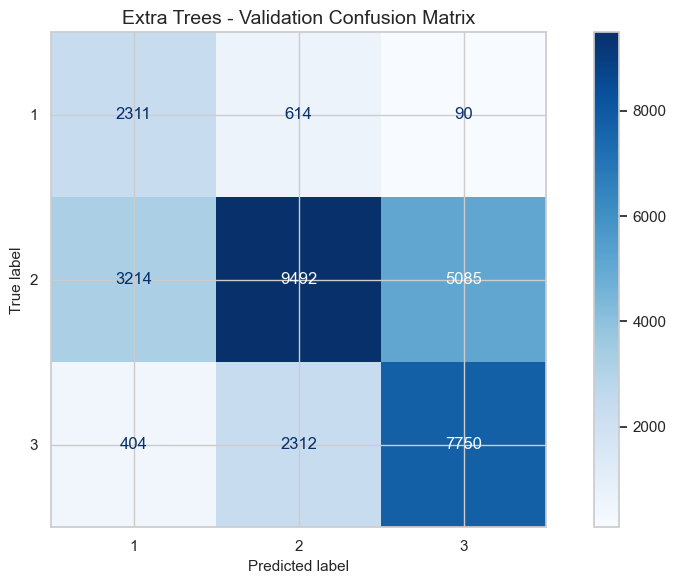

In [66]:
cm_et = confusion_matrix(
    y_val,
    et_predictions,
    labels=[1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_et,
    display_labels=[1, 2, 3]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Extra Trees - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

Step 6. Train Model 4 – XGBoost Classifier

## 15. Model 4 - XGBoost Classifier

XGBoost is an advanced gradient boosting algorithm that builds decision trees sequentially.

Each new tree attempts to improve the predictions made by previous trees by learning from their errors.

The histogram-based tree method is used to improve computational efficiency.

Class-balanced sample weights are applied to address the imbalance in the damage grade distribution.

The model is evaluated using the same validation metrics as the previous models.

In [69]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)
print("XGBoost imported successfully!")

XGBoost version: 2.1.4
XGBoost imported successfully!


In [70]:
from sklearn.utils.class_weight import compute_sample_weight

# Convert original damage grades to zero-based labels
y_fit_xgb = y_fit - 1
y_val_xgb = y_val - 1

# Calculate balanced sample weights
xgb_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_fit
)

print("Original target classes:", sorted(y_fit.unique()))
print("XGBoost target classes:", sorted(y_fit_xgb.unique()))

print("\nSample weights calculated successfully!")
print("Sample weights shape:", xgb_sample_weights.shape)

Original target classes: [np.int64(1), np.int64(2), np.int64(3)]
XGBoost target classes: [np.int64(0), np.int64(1), np.int64(2)]

Sample weights calculated successfully!
Sample weights shape: (177208,)


In [71]:
from sklearn.utils.class_weight import compute_sample_weight

# Convert original damage grades to zero-based labels
y_fit_xgb = y_fit - 1
y_val_xgb = y_val - 1

# Calculate balanced sample weights
xgb_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_fit
)

print("Original target classes:", sorted(y_fit.unique()))
print("XGBoost target classes:", sorted(y_fit_xgb.unique()))

print("\nSample weights calculated successfully!")
print("Sample weights shape:", xgb_sample_weights.shape)

Original target classes: [np.int64(1), np.int64(2), np.int64(3)]
XGBoost target classes: [np.int64(0), np.int64(1), np.int64(2)]

Sample weights calculated successfully!
Sample weights shape: (177208,)


In [72]:
xgb_model = xgb.XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_lambda=1,
    tree_method="hist",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

print("XGBoost model created successfully!")

XGBoost model created successfully!


In [73]:
xgb_model.fit(
    X_fit_processed,
    y_fit_xgb,
    sample_weight=xgb_sample_weights,
    verbose=False
)

print("XGBoost model training completed!")

XGBoost model training completed!


In [74]:
# Predict zero-based labels
xgb_predictions_encoded = xgb_model.predict(
    X_val_processed
)

# Convert predictions back to original damage grades
xgb_predictions = xgb_predictions_encoded + 1

print("XGBoost predictions generated successfully!")

print("\nFirst 20 predictions:")
print(xgb_predictions[:20])

XGBoost predictions generated successfully!

First 20 predictions:
[1 3 3 2 2 2 2 2 2 2 2 3 2 3 3 3 2 1 2 3]


In [75]:
xgb_accuracy = accuracy_score(y_val, xgb_predictions)

xgb_precision = precision_score(
    y_val, xgb_predictions,
    average="weighted",
    zero_division=0
)

xgb_recall = recall_score(
    y_val, xgb_predictions,
    average="weighted",
    zero_division=0
)

xgb_macro_f1 = f1_score(
    y_val, xgb_predictions,
    average="macro",
    zero_division=0
)

xgb_weighted_f1 = f1_score(
    y_val, xgb_predictions,
    average="weighted",
    zero_division=0
)

xgb_mae = mean_absolute_error(y_val, xgb_predictions)

print("XGBOOST MODEL PERFORMANCE")
print("-" * 45)

print(f"Accuracy:            {xgb_accuracy:.4f}")
print(f"Precision:           {xgb_precision:.4f}")
print(f"Recall:              {xgb_recall:.4f}")
print(f"Macro F1-score:      {xgb_macro_f1:.4f}")
print(f"Weighted F1-score:   {xgb_weighted_f1:.4f}")
print(f"Mean Absolute Error: {xgb_mae:.4f}")

XGBOOST MODEL PERFORMANCE
---------------------------------------------
Accuracy:            0.6586
Precision:           0.6987
Recall:              0.6586
Macro F1-score:      0.6341
Weighted F1-score:   0.6648
Mean Absolute Error: 0.3560


In [76]:
print(
    classification_report(
        y_val,
        xgb_predictions,
        labels=[1, 2, 3],
        target_names=[
            "Grade 1 - Low Damage",
            "Grade 2 - Medium Damage",
            "Grade 3 - Severe Damage"
        ],
        zero_division=0
    )
)

                         precision    recall  f1-score   support

   Grade 1 - Low Damage       0.41      0.82      0.55      3015
Grade 2 - Medium Damage       0.78      0.60      0.68     17791
Grade 3 - Severe Damage       0.65      0.72      0.68     10466

               accuracy                           0.66     31272
              macro avg       0.61      0.71      0.63     31272
           weighted avg       0.70      0.66      0.66     31272



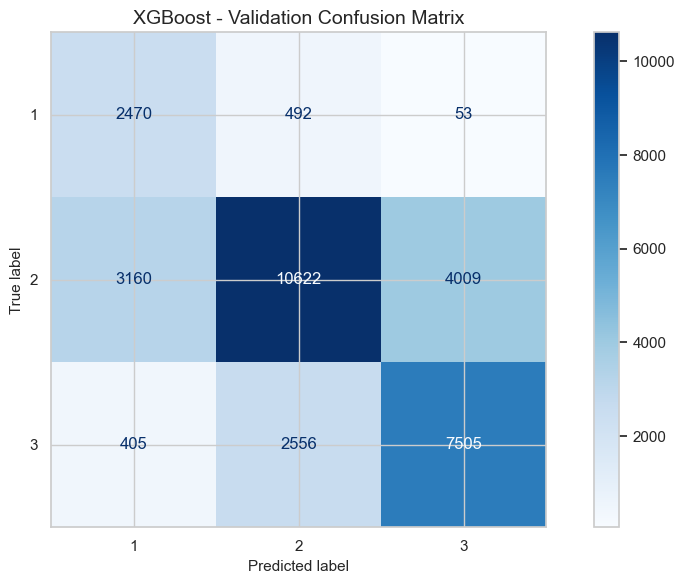

In [77]:
cm_xgb = confusion_matrix(
    y_val,
    xgb_predictions,
    labels=[1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=[1, 2, 3]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("XGBoost - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

Fair model comparison

In [78]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    mean_absolute_error
)

# Decision Tree on validation data
dt_validation_model = DecisionTreeClassifier(
    max_depth=20,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42
)

dt_validation_model.fit(X_fit_processed, y_fit)
dt_val_predictions = dt_validation_model.predict(X_val_processed)


# Random Forest on validation data
rf_validation_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_split=20,
    min_samples_leaf=10,
    max_features="sqrt",
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf_validation_model.fit(X_fit_processed, y_fit)
rf_val_predictions = rf_validation_model.predict(X_val_processed)


print("Decision Tree and Random Forest validation completed!")

Decision Tree and Random Forest validation completed!


Calculate validation performance for all four models

In [79]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error
)

# Store all model predictions
validation_predictions = {
    "Decision Tree": dt_val_predictions,
    "Random Forest": rf_val_predictions,
    "Extra Trees": et_predictions,
    "XGBoost": xgb_predictions
}

# Calculate evaluation metrics
validation_results = []

for model_name, predictions in validation_predictions.items():

    validation_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Weighted Precision": precision_score(
            y_val, predictions, average="weighted", zero_division=0
        ),
        "Weighted Recall": recall_score(
            y_val, predictions, average="weighted", zero_division=0
        ),
        "Macro F1": f1_score(
            y_val, predictions, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_val, predictions, average="weighted", zero_division=0
        ),
        "MAE": mean_absolute_error(y_val, predictions)
    })

# Create comparison DataFrame
validation_comparison = pd.DataFrame(validation_results)

# Sort by Macro F1
validation_comparison = validation_comparison.sort_values(
    by="Macro F1", ascending=False
).reset_index(drop=True)

print("MODEL VALIDATION COMPARISON")
print("=" * 90)

display(
    validation_comparison.style.format({
        "Accuracy": "{:.4f}",
        "Weighted Precision": "{:.4f}",
        "Weighted Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}",
        "MAE": "{:.4f}"
    })
)

MODEL VALIDATION COMPARISON


,Model,Accuracy,Weighted Precision,Weighted Recall,Macro F1,Weighted F1,MAE
0,XGBoost,0.6586,0.6987,0.6586,0.6341,0.6648,0.3560
1,Decision Tree,0.6452,0.6825,0.6452,0.6167,0.6521,0.3709
2,Extra Trees,0.6253,0.6731,0.6253,0.6026,0.6291,0.3905
3,Random Forest,0.6176,0.6667,0.6176,0.5960,0.6201,0.3981


Compare performance for each damage grade

In [80]:
from sklearn.metrics import classification_report
import pandas as pd

class_results = []

for model_name, predictions in validation_predictions.items():

    report = classification_report(
        y_val,
        predictions,
        labels=[1, 2, 3],
        output_dict=True,
        zero_division=0
    )

    for grade in ["1", "2", "3"]:
        class_results.append({
            "Model": model_name,
            "Damage Grade": f"Grade {grade}",
            "Precision": report[grade]["precision"],
            "Recall": report[grade]["recall"],
            "F1-score": report[grade]["f1-score"]
        })

class_comparison = pd.DataFrame(class_results)

display(
    class_comparison.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}"
    })
)

,Model,Damage Grade,Precision,Recall,F1-score
0,Decision Tree,Grade 1,0.3909,0.7638,0.5171
1,Decision Tree,Grade 2,0.7575,0.5951,0.6666
2,Decision Tree,Grade 3,0.6389,0.6961,0.6663
3,Random Forest,Grade 1,0.3922,0.7476,0.5145
4,Random Forest,Grade 2,0.7616,0.5175,0.6162
5,Random Forest,Grade 3,0.5845,0.7504,0.6572
6,Extra Trees,Grade 1,0.3898,0.7665,0.5168
7,Extra Trees,Grade 2,0.7644,0.5335,0.6284
8,Extra Trees,Grade 3,0.5996,0.7405,0.6626
9,XGBoost,Grade 1,0.4093,0.8192,0.5459


Confusion matrix comparison

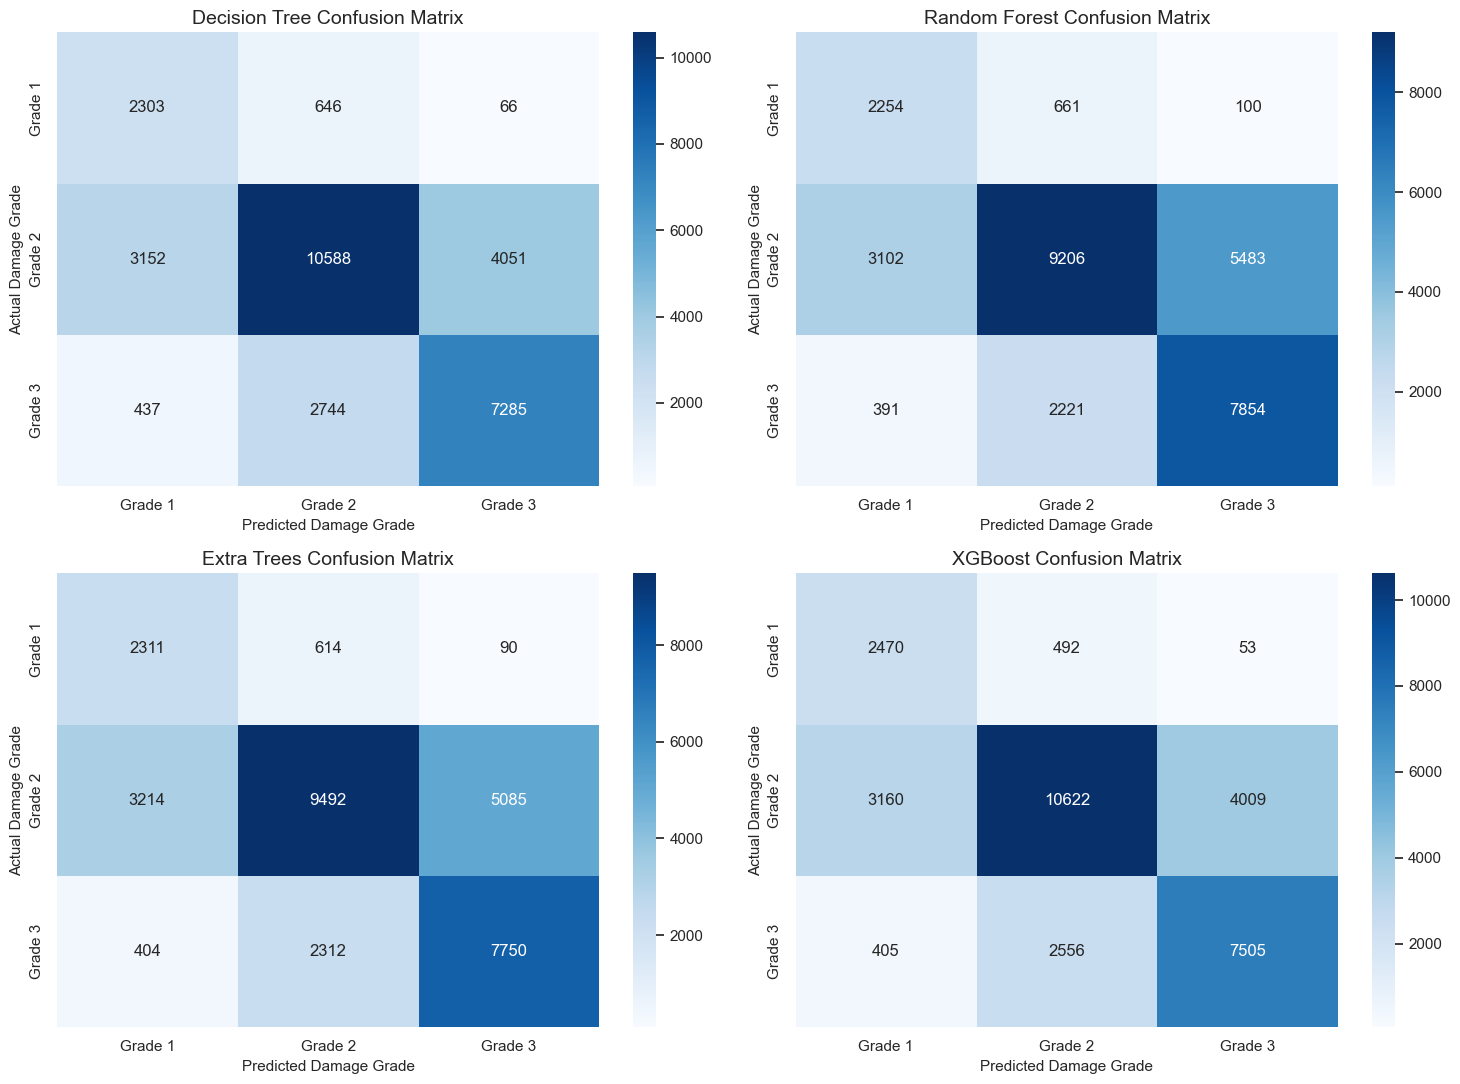

In [81]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

model_names = [
    "Decision Tree",
    "Random Forest",
    "Extra Trees",
    "XGBoost"
]

for ax, model_name in zip(axes.flatten(), model_names):

    predictions = validation_predictions[model_name]

    cm = confusion_matrix(
        y_val,
        predictions,
        labels=[1, 2, 3]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Grade 1", "Grade 2", "Grade 3"],
        yticklabels=["Grade 1", "Grade 2", "Grade 3"],
        ax=ax
    )

    ax.set_title(f"{model_name} Confusion Matrix")
    ax.set_xlabel("Predicted Damage Grade")
    ax.set_ylabel("Actual Damage Grade")

plt.tight_layout()
plt.show()

XGBoost hyperparameter tuning

In [82]:
import xgboost as xgb
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    mean_absolute_error,
    recall_score
)

# Three alternative configurations
tuning_configs = {
    "XGBoost_Tuned_1": {
        "n_estimators": 300,
        "max_depth": 4,
        "learning_rate": 0.05
    },
    "XGBoost_Tuned_2": {
        "n_estimators": 250,
        "max_depth": 6,
        "learning_rate": 0.05
    },
    "XGBoost_Tuned_3": {
        "n_estimators": 200,
        "max_depth": 8,
        "learning_rate": 0.05
    }
}

tuned_models = {}
tuned_predictions = {}
tuning_results = []

for model_name, params in tuning_configs.items():

    print(f"\nTraining {model_name}...")

    model = xgb.XGBClassifier(
        objective="multi:softprob",
        num_class=3,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_lambda=1,
        tree_method="hist",
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1,
        **params
    )

    model.fit(
        X_fit_processed,
        y_fit_xgb,
        sample_weight=xgb_sample_weights,
        verbose=False
    )

    predictions = model.predict(X_val_processed) + 1

    tuned_models[model_name] = model
    tuned_predictions[model_name] = predictions

    report = classification_report(
        y_val,
        predictions,
        labels=[1, 2, 3],
        output_dict=True,
        zero_division=0
    )

    tuning_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro F1": f1_score(
            y_val, predictions, average="macro"
        ),
        "Weighted F1": f1_score(
            y_val, predictions, average="weighted"
        ),
        "MAE": mean_absolute_error(y_val, predictions),
        "Grade 3 Recall": report["3"]["recall"]
    })

    print(f"{model_name} training completed!")

# Display tuning comparison
tuning_comparison = pd.DataFrame(tuning_results)

display(
    tuning_comparison.sort_values(
        by="Macro F1",
        ascending=False
    ).reset_index(drop=True).style.format({
        "Accuracy": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}",
        "MAE": "{:.4f}",
        "Grade 3 Recall": "{:.4f}"
    })
)


Training XGBoost_Tuned_1...
XGBoost_Tuned_1 training completed!

Training XGBoost_Tuned_2...
XGBoost_Tuned_2 training completed!

Training XGBoost_Tuned_3...
XGBoost_Tuned_3 training completed!


,Model,Accuracy,Macro F1,Weighted F1,MAE,Grade 3 Recall
0,XGBoost_Tuned_3,0.6588,0.6343,0.6647,0.3553,0.7143
1,XGBoost_Tuned_2,0.6511,0.6267,0.6573,0.3638,0.7066
2,XGBoost_Tuned_1,0.6385,0.6139,0.6450,0.3776,0.6959


Compare original and tuned XGBoost by damage grade

In [83]:
from sklearn.metrics import classification_report
import pandas as pd

xgb_class_predictions = {
    "Original XGBoost": xgb_predictions,
    "Tuned XGBoost 3": tuned_predictions["XGBoost_Tuned_3"]
}

class_results_xgb = []

for model_name, predictions in xgb_class_predictions.items():

    report = classification_report(
        y_val,
        predictions,
        labels=[1, 2, 3],
        output_dict=True,
        zero_division=0
    )

    for grade in ["1", "2", "3"]:
        class_results_xgb.append({
            "Model": model_name,
            "Damage Grade": f"Grade {grade}",
            "Precision": report[grade]["precision"],
            "Recall": report[grade]["recall"],
            "F1-score": report[grade]["f1-score"]
        })

xgb_class_comparison = pd.DataFrame(class_results_xgb)

display(
    xgb_class_comparison.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}"
    })
)

,Model,Damage Grade,Precision,Recall,F1-score
0,Original XGBoost,Grade 1,0.4093,0.8192,0.5459
1,Original XGBoost,Grade 2,0.7770,0.5970,0.6752
2,Original XGBoost,Grade 3,0.6488,0.7171,0.6813
3,Tuned XGBoost 3,Grade 1,0.4128,0.8129,0.5475
4,Tuned XGBoost 3,Grade 2,0.7742,0.6000,0.6760
5,Tuned XGBoost 3,Grade 3,0.6475,0.7143,0.6793


Final model training and test evaluation

In [84]:
import xgboost as xgb
import numpy as np

from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    classification_report,
    confusion_matrix
)

# Step 1: Prepare target labels
y_train_xgb = y_train - 1

# Step 2: Calculate balanced sample weights
final_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

# Step 3: Create final XGBoost model
final_xgb_model = xgb.XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_lambda=1,
    tree_method="hist",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

# Step 4: Train using the complete training dataset
final_xgb_model.fit(
    X_train_processed,
    y_train_xgb,
    sample_weight=final_sample_weights,
    verbose=False
)

print("Final XGBoost model training completed!")

# Step 5: Generate test predictions
final_test_predictions = final_xgb_model.predict(
    X_test_processed
) + 1

print("Final test predictions generated!")

# Step 6: Calculate test metrics
final_accuracy = accuracy_score(
    y_test, final_test_predictions
)

final_precision = precision_score(
    y_test, final_test_predictions,
    average="weighted", zero_division=0
)

final_recall = recall_score(
    y_test, final_test_predictions,
    average="weighted", zero_division=0
)

final_macro_f1 = f1_score(
    y_test, final_test_predictions,
    average="macro", zero_division=0
)

final_weighted_f1 = f1_score(
    y_test, final_test_predictions,
    average="weighted", zero_division=0
)

final_mae = mean_absolute_error(
    y_test, final_test_predictions
)

print("\nFINAL XGBOOST TEST PERFORMANCE")
print("-" * 45)
print(f"Accuracy:           {final_accuracy:.4f}")
print(f"Weighted Precision: {final_precision:.4f}")
print(f"Weighted Recall:    {final_recall:.4f}")
print(f"Macro F1-score:     {final_macro_f1:.4f}")
print(f"Weighted F1-score:  {final_weighted_f1:.4f}")
print(f"Mean Absolute Error:{final_mae:.4f}")

# Step 7: Classification report
print("\nFINAL CLASSIFICATION REPORT")

print(classification_report(
    y_test,
    final_test_predictions,
    labels=[1, 2, 3],
    target_names=[
        "Grade 1 - Low Damage",
        "Grade 2 - Medium Damage",
        "Grade 3 - Severe Damage"
    ],
    zero_division=0
))

# Step 8: Confusion matrix
final_cm = confusion_matrix(
    y_test,
    final_test_predictions,
    labels=[1, 2, 3]
)

print("FINAL CONFUSION MATRIX")
print(final_cm)

Final XGBoost model training completed!
Final test predictions generated!

FINAL XGBOOST TEST PERFORMANCE
---------------------------------------------
Accuracy:           0.6620
Weighted Precision: 0.7020
Weighted Recall:    0.6620
Macro F1-score:     0.6381
Weighted F1-score:  0.6679
Mean Absolute Error:0.3520

FINAL CLASSIFICATION REPORT
                         precision    recall  f1-score   support

   Grade 1 - Low Damage       0.41      0.82      0.55      5025
Grade 2 - Medium Damage       0.78      0.60      0.68     29652
Grade 3 - Severe Damage       0.65      0.72      0.69     17444

               accuracy                           0.66     52121
              macro avg       0.62      0.72      0.64     52121
           weighted avg       0.70      0.66      0.67     52121

FINAL CONFUSION MATRIX
[[ 4144   786    95]
 [ 5223 17730  6699]
 [  634  4179 12631]]


Final model and preprocessor

In [85]:
import joblib
import json
from pathlib import Path

# Create models directory
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Save final XGBoost model
joblib.dump(
    final_xgb_model,
    models_dir / "earthquake_xgboost_model.pkl"
)

# Save fitted preprocessing pipeline
joblib.dump(
    preprocessor,
    models_dir / "earthquake_preprocessor.pkl"
)

# Save model information
model_metadata = {
    "project": "Earthquake Damage Prediction",
    "model": "XGBoost Classifier",
    "xgboost_version": xgb.__version__,
    "target_classes": {
        "1": "Low Damage",
        "2": "Medium Damage",
        "3": "Severe Damage"
    },
    "test_accuracy": round(final_accuracy, 4),
    "test_macro_f1": round(final_macro_f1, 4),
    "test_weighted_f1": round(final_weighted_f1, 4),
    "test_mae": round(final_mae, 4),
    "training_records": len(X_train),
    "test_records": len(X_test),
    "input_features": list(X.columns)
}

with open(
    models_dir / "model_metadata.json",
    "w"
) as file:
    json.dump(model_metadata, file, indent=4)

print("All final model files saved successfully!")

print("\nSaved files:")
for file_path in models_dir.iterdir():
    if file_path.is_file():
        print(file_path.name, "-", round(file_path.stat().st_size / 1024, 2), "KB")

All final model files saved successfully!

Saved files:
model_metadata.json - 1.71 KB
earthquake_preprocessor.pkl - 294.62 KB
earthquake_xgboost_model.pkl - 1621.57 KB


In [86]:
import joblib
import numpy as np
from pathlib import Path

# Load saved files
models_dir = Path("../models")

loaded_model = joblib.load(
    models_dir / "earthquake_xgboost_model.pkl"
)

loaded_preprocessor = joblib.load(
    models_dir / "earthquake_preprocessor.pkl"
)

# Take five original, unprocessed test records
sample_buildings = X_test.head(5)

# Apply saved preprocessing
sample_processed = loaded_preprocessor.transform(
    sample_buildings
)

# Generate predictions
sample_predictions = loaded_model.predict(
    sample_processed
) + 1

# Display results
prediction_results = pd.DataFrame({
    "Building ID": sample_buildings.index,
    "Predicted Damage Grade": sample_predictions,
    "Damage Category": pd.Series(sample_predictions).map({
        1: "Low Damage",
        2: "Medium Damage",
        3: "Severe Damage"
    }).values
})

display(prediction_results)

print("Saved model and preprocessor loaded successfully!")
print("Prediction test completed successfully!")

,Building ID,Predicted Damage Grade,Damage Category
0,124536,2,Medium Damage
1,112152,2,Medium Damage
2,93613,1,Low Damage
3,204895,2,Medium Damage
4,37356,3,Severe Damage


Saved model and preprocessor loaded successfully!
Prediction test completed successfully!



##  Model Comparison Report

### 1. Objective
Multiple machine learning classification algorithms were evaluated to identify the most suitable model for predicting earthquake damage grades in buildings.

The target variable contains three classes:
- Grade 1: Low Damage
- Grade 2: Medium Damage
- Grade 3: Severe Damage

### 2. Models Evaluated
The following models were evaluated using the same validation dataset:

1. Decision Tree Classifier
2. Random Forest Classifier
3. Extra Trees Classifier
4. XGBoost Classifier

### 3. Validation Performance Comparison

| Model | Accuracy | Macro F1 | Weighted F1 | MAE |
|---|---:|---:|---:|---:|
| XGBoost | 0.6586 | 0.6341 | 0.6648 | 0.3560 |
| Decision Tree | 0.6452 | 0.6167 | 0.6521 | 0.3709 |
| Extra Trees | 0.6253 | 0.6026 | 0.6291 | 0.3905 |
| Random Forest | 0.6176 | 0.5960 | 0.6201 | 0.3981 |

### 4. Final Model Selection

XGBoost was selected as the final model because it achieved the best overall validation performance.

It obtained:
- Accuracy: 65.86%
- Macro F1-score: 0.6341
- Weighted F1-score: 0.6648
- Mean Absolute Error: 0.3560

XGBoost also achieved the highest Grade 1, Grade 2 and Grade 3 F1-scores among the evaluated models.

Random Forest achieved a slightly higher recall for Grade 3 (0.7504), making it a possible alternative when identifying severe damage is the main priority.

### 5. Final Test Performance

After selecting XGBoost, the model was trained using the full training dataset and evaluated on the test split.

| Metric | Final Test Result |
|---|---:|
| Accuracy | 66.20% |
| Weighted Precision | 0.7020 |
| Weighted Recall | 0.6620 |
| Macro F1-score | 0.6381 |
| Weighted F1-score | 0.6679 |
| Mean Absolute Error | 0.3520 |

### 6. Conclusion

XGBoost is the recommended model among the evaluated candidates because it provides the strongest overall balance of classification performance.

However, the model still confuses some medium-damage and severe-damage buildings. Therefore, its predictions should be used as a decision-support tool and not as a replacement for professional structural inspections.

**Evaluation note:** The validation dataset was used for model comparison and hyperparameter experiments. The test split was also used in preliminary baseline, Decision Tree and Random Forest experiments before the final evaluation. Therefore, the final test results should be interpreted with this limitation in mind.



# 15. Model Comparison Report

## 15.1 Objective

The objective of model comparison was to identify the best machine learning algorithm for predicting earthquake damage grades.

We evaluated four machine learning algorithms:
1. Decision Tree Classifier
2. Random Forest Classifier
3. Extra Trees Classifier
4. XGBoost Classifier

All models were evaluated using the same validation dataset.

## 15.2 Performance Comparison

| Model | Accuracy | Macro F1 | Weighted F1 | MAE |
|---|---:|---:|---:|---:|
| XGBoost | 0.6586 | 0.6341 | 0.6648 | 0.3560 |
| Decision Tree | 0.6452 | 0.6167 | 0.6521 | 0.3709 |
| Extra Trees | 0.6253 | 0.6026 | 0.6291 | 0.3905 |
| Random Forest | 0.6176 | 0.5960 | 0.6201 | 0.3981 |

## 15.3 Best Model Selection

XGBoost achieved the best overall validation performance.

Its validation results were:
- Accuracy: 65.86%
- Macro F1-score: 0.6341
- Weighted F1-score: 0.6648
- Mean Absolute Error: 0.3560

Random Forest achieved slightly higher recall for Grade 3, but XGBoost provided better overall performance across the main evaluation metrics.

## 15.4 Hyperparameter Tuning

We tested different XGBoost configurations by changing:
- Number of estimators
- Maximum tree depth
- Learning rate

The tuned configuration with maximum depth 8 achieved marginally higher accuracy and macro F1, while the original configuration achieved slightly higher weighted F1 and Grade 3 recall.

Therefore, we retained the original XGBoost configuration as the final candidate.

## 15.5 Final Model Performance

After model selection, we retrained XGBoost using the complete training dataset.

Final test results:
- Accuracy: 66.20%
- Macro F1-score: 0.6381
- Weighted F1-score: 0.6679
- Mean Absolute Error: 0.3520

## 15.6 Conclusion

XGBoost was selected as the final model because it provided the strongest overall balance of predictive performance across the evaluated models.

The model can support building damage assessment, but its predictions should be combined with professional structural inspections and engineering expertise.



# 16. Challenges Faced Report

During the Earthquake Damage Prediction project, several challenges were encountered and addressed.

## 16.1 Large Dataset

**Challenge:** The dataset contained 260,601 building records and 39 input features, making data processing and model training computationally demanding.

**Solution:** We used Pandas, efficient preprocessing, sparse feature encoding, and tree-based machine learning algorithms.

## 16.2 Class Imbalance

**Challenge:** The target variable contained an unequal distribution of damage grades. Grade 2 represented approximately 56.89% of the dataset, while Grade 1 represented only 9.64%.

**Solution:** We used stratified train-test splitting and balanced sample weights during XGBoost training to give greater importance to underrepresented classes.

## 16.3 High-Cardinality Geographic Features

**Challenge:** Geographic features such as geo_level_2_id and geo_level_3_id contained many unique categories.

**Solution:** We used OneHotEncoder with min_frequency=50 and handle_unknown="infrequent_if_exist" for geographic features to group infrequent categories and handle unseen values.

## 16.4 Categorical Data Processing

**Challenge:** Several building characteristics were categorical and could not be directly used by the machine learning models.

**Solution:** We used OneHotEncoder to convert categorical features into numerical representations and ColumnTransformer to apply different preprocessing operations.

## 16.5 Model Performance Differences

**Challenge:** Different machine learning algorithms produced different results, and selecting the best model required careful evaluation.

**Solution:** We compared Decision Tree, Random Forest, Extra Trees, and XGBoost using accuracy, precision, recall, F1-score, and MAE.

## 16.6 XGBoost Installation Issue on macOS

**Challenge:** Initially, XGBoost could not be imported because the required OpenMP library was missing.

**Solution:** We installed the required dependency using Homebrew:

brew install libomp

After installation, XGBoost imported and worked successfully.

## 16.7 Distinguishing Between Damage Grades

**Challenge:** The model sometimes confused Grade 2 and Grade 3 buildings.

**Solution:** We analysed the confusion matrix and class-wise precision, recall, and F1-scores to understand model errors.

## 16.8 Conclusion

These challenges helped improve our understanding of data preprocessing, class imbalance, categorical encoding, model selection, and machine learning evaluation.



# 17. Suggestions for Seismologists

Based on the analysis and findings of this project, the following suggestions may help seismologists, disaster management authorities, and structural engineers improve earthquake damage assessment and preparedness.

## 17.1 Identify Vulnerable Buildings

Use building characteristics and damage prediction results to identify potentially vulnerable buildings and prioritise them for professional structural inspection.

## 17.2 Improve Building Construction Quality

Encourage earthquake-resistant construction practices, suitable foundation designs, and the use of appropriate construction materials.

## 17.3 Strengthen Building Regulations

Promote compliance with earthquake-resistant building codes and conduct regular structural safety inspections, especially in earthquake-prone regions.

## 17.4 Focus on High-Risk Geographic Areas

Use geographic analysis to identify locations where buildings may have higher damage vulnerability. Prioritise these areas for risk assessment and disaster preparedness.

## 17.5 Maintain Updated Building Records

Maintain accurate and updated information about building age, height, number of floors, construction materials, foundation type, and geographic location.

## 17.6 Improve Disaster Preparedness

Develop emergency response plans, evacuation procedures, public awareness programmes, and preparedness activities in vulnerable communities.

## 17.7 Combine Machine Learning with Seismic Information

Combine building damage prediction with seismic hazard maps, earthquake intensity information, soil conditions, and professional engineering assessments to improve risk evaluation.

## 17.8 Conclusion

Machine learning can support earthquake damage assessment by helping identify buildings that may require attention. However, predictions should be treated as decision-support information and should never replace physical inspections or professional structural engineering assessments.

The long-term goal should be to improve building safety, reduce earthquake-related damage, and protect human lives.



# 18. Model Explainability – Feature Importance Analysis

## 18.1 Introduction

Model explainability helps us understand which input features contribute most to the predictions made by a machine learning model.

In this project, we used XGBoost feature importance to identify the most influential features used by the final trained model.

## 18.2 Objective

The objective is to identify the top features that the XGBoost model considers important when predicting building damage grades.

## 18.3 Methodology

We extracted feature importance values from the trained XGBoost model and matched them with the transformed feature names generated by the preprocessing pipeline.

We then ranked the features and visualised the top 20 features.

## 18.4 Interpretation

Features with higher importance values contributed more to the model's prediction process according to its feature-importance measure.

These values indicate model reliance and do not prove that a feature directly causes earthquake damage.


,Feature,Importance
5,ordinary_cat__foundation_type_r,0.048039
787,geo_cat__geo_level_2_id_1149,0.022674
51,geo_cat__geo_level_1_id_13,0.021571
64,geo_cat__geo_level_1_id_26,0.020833
55,geo_cat__geo_level_1_id_17,0.016418
1719,numerical__has_superstructure_mud_mortar_stone,0.012062
46,geo_cat__geo_level_1_id_8,0.011945
60,geo_cat__geo_level_1_id_22,0.011593
58,geo_cat__geo_level_1_id_20,0.010693
59,geo_cat__geo_level_1_id_21,0.009318


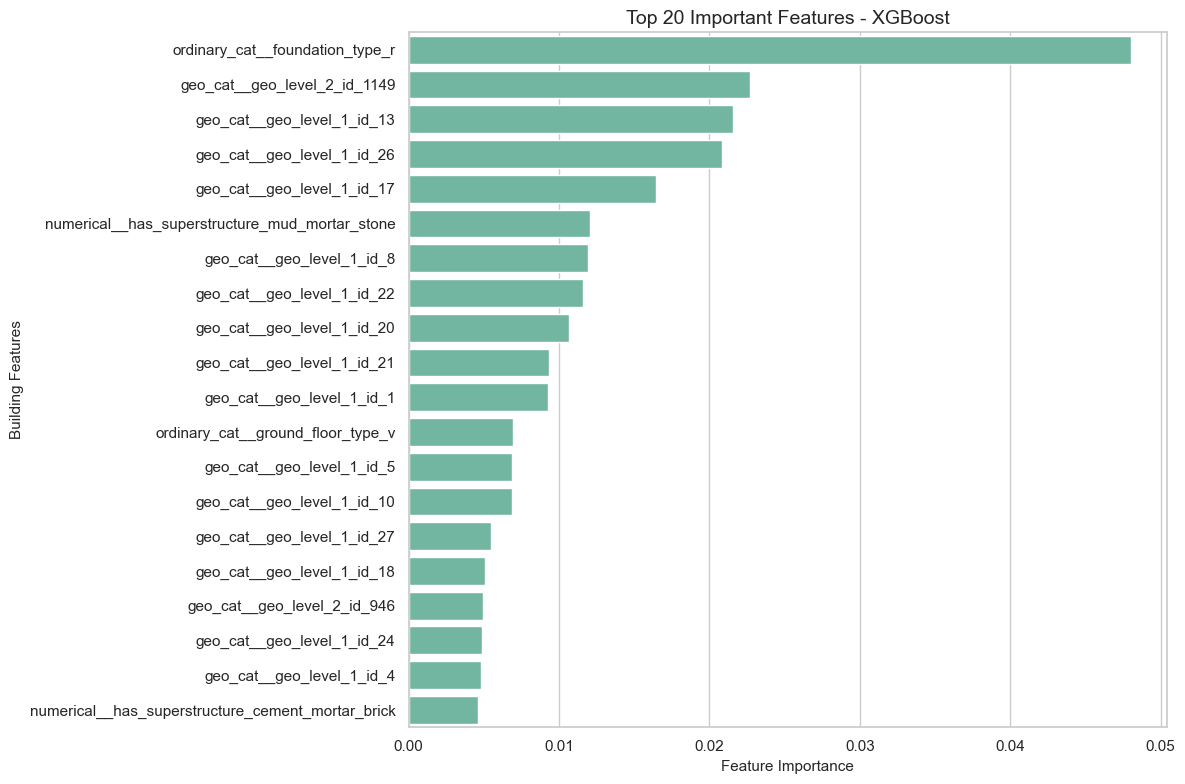

In [87]:

# Extract feature names from the fitted preprocessor

feature_names = preprocessor.get_feature_names_out()

# Extract feature importance from the final XGBoost model

feature_importances = final_xgb_model.feature_importances_

# Create a DataFrame

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
})

# Sort features by importance

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top 20 features

top_20_features = importance_df.head(20)

display(top_20_features)

# Visualize top 20 features

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_20_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Important Features - XGBoost")
plt.xlabel("Feature Importance")
plt.ylabel("Building Features")
plt.tight_layout()
plt.show()



# 19. Prediction Confidence Analysis

## 19.1 Introduction

In this section, we analyse the prediction probabilities generated by the final XGBoost model.

Instead of displaying only the predicted damage grade, we examine the probability assigned to each damage category.

## 19.2 Objective

The objective is to understand how strongly the model favours each damage category and to identify predictions where the model is less certain.

## 19.3 Conclusion

Prediction probabilities provide additional information about model outputs. However, they should not automatically be interpreted as calibrated real-world probabilities or guarantees of building safety.


,Building ID,Actual Damage Grade,Predicted Damage Grade,Low Damage Probability,Medium Damage Probability,Severe Damage Probability,Prediction Confidence
0,449925,3,2,0.032710,0.624087,0.343203,0.624087
1,661669,2,2,0.259140,0.482302,0.258558,0.482302
2,1001567,2,1,0.876915,0.069835,0.053250,0.876915
3,904649,2,2,0.144094,0.620130,0.235775,0.620130
4,978604,3,3,0.024105,0.312664,0.663231,0.663231
5,906232,3,2,0.197503,0.547437,0.255060,0.547437
6,347374,3,3,0.065957,0.342142,0.591901,0.591901
7,138918,2,1,0.792658,0.168619,0.038723,0.792658
8,162214,2,3,0.032739,0.377182,0.590079,0.590079
9,498969,2,2,0.076507,0.521385,0.402108,0.521385


Average maximum prediction probability: 0.6296


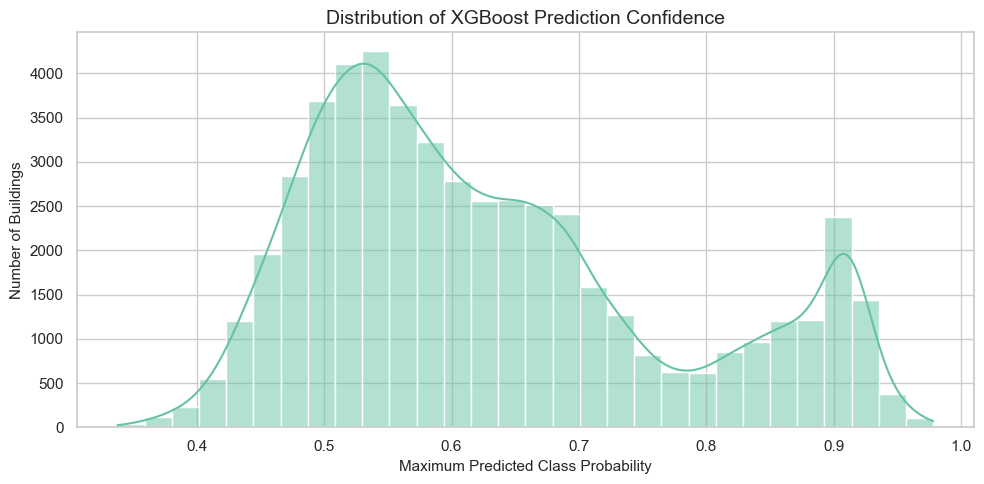

In [88]:

# Generate prediction probabilities for test data

test_probabilities = final_xgb_model.predict_proba(X_test_processed)

# Get predicted damage grades (1, 2, 3)

confidence_predictions = np.argmax(test_probabilities, axis=1) + 1

# Get maximum prediction probability

prediction_confidence = np.max(test_probabilities, axis=1)

# Create prediction analysis DataFrame

confidence_df = pd.DataFrame({
    "Building ID": df.loc[X_test.index, "building_id"].values,
    "Actual Damage Grade": y_test.values,
    "Predicted Damage Grade": confidence_predictions,
    "Low Damage Probability": test_probabilities[:, 0],
    "Medium Damage Probability": test_probabilities[:, 1],
    "Severe Damage Probability": test_probabilities[:, 2],
    "Prediction Confidence": prediction_confidence
})

# Display first 10 predictions

display(confidence_df.head(10))

# Analyse average maximum probability

print(
    "Average maximum prediction probability:",
    round(prediction_confidence.mean(), 4)
)

# Plot confidence distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    prediction_confidence,
    bins=30,
    kde=True
)

plt.title("Distribution of XGBoost Prediction Confidence")
plt.xlabel("Maximum Predicted Class Probability")
plt.ylabel("Number of Buildings")

plt.tight_layout()
plt.show()
